In [1]:

from pathlib import Path
import os

CHECKPOINT = Path(
    "/kaggle/input/datasets/aryan210107/"
    "lungvision-ai-disease-classification-result/"
    "lungvision_disease_classification/checkpoints/"
    "densenet121_nih_best.pth"
)

HISTORY = Path(
    "/kaggle/input/datasets/aryan210107/"
    "lungvision-ai-disease-classification-result/"
    "lungvision_disease_classification/nih_training_history.csv"
)

print("Checkpoint exists:", CHECKPOINT.is_file())
print("History exists:", HISTORY.is_file())

if CHECKPOINT.is_file():
    print("Checkpoint size:", round(CHECKPOINT.stat().st_size / 1024**2, 2), "MB")


Checkpoint exists: True
History exists: True
Checkpoint size: 80.55 MB


In [2]:

import torch
import torch.nn as nn
import pandas as pd
from torchvision import models

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

LABELS = [
    "Cardiomegaly",
    "Edema",
    "Consolidation",
    "Pneumonia",
    "Atelectasis",
    "Pneumothorax"
]

checkpoint = torch.load(
    CHECKPOINT,
    map_location=DEVICE,
    weights_only=True
)

model = models.densenet121(weights=None)

model.classifier = nn.Linear(
    model.classifier.in_features,
    len(LABELS)
)

model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(DEVICE)
model.eval()

history_df = pd.read_csv(HISTORY)

print("Model loaded successfully!")
print("Checkpoint epoch:", checkpoint["epoch"])
print("Best validation AUROC:", checkpoint["best_val_auc"])
print("Architecture: DenseNet121")
print("Output classes:", len(LABELS))
print("Device:", DEVICE)

display(history_df)


Model loaded successfully!
Checkpoint epoch: 4
Best validation AUROC: 0.8205820182751643
Architecture: DenseNet121
Output classes: 6
Device: cuda


,epoch,train_loss,val_loss,macro_auc,macro_auprc,learning_rate,epoch_time_sec
0,1,1.105683,1.132232,0.808754,0.137820,0.0001,2828.587773
1,2,1.006306,1.102983,0.814312,0.162032,0.0001,2242.214946
2,3,0.933060,1.266051,0.801935,0.159012,0.0001,2068.863248
3,4,0.847063,1.333251,0.820582,0.166984,0.0001,2029.730595
4,5,0.710669,1.694733,0.817196,0.164999,0.0001,1983.076374


In [3]:

from pathlib import Path

ARTIFACT_DIR = Path(
    "/kaggle/input/datasets/aryan210107/"
    "lungvision-ai-disease-classification-result/"
    "lungvision_disease_classification"
)

MANIFEST = ARTIFACT_DIR / "nih_manifest.csv"

CHECKPOINT = (
    ARTIFACT_DIR / "checkpoints" /
    "densenet121_nih_best.pth"
)

HISTORY = ARTIFACT_DIR / "nih_training_history.csv"

for name, path in {
    "Manifest": MANIFEST,
    "Checkpoint": CHECKPOINT,
    "History": HISTORY
}.items():
    print(f"{name}: {'FOUND' if path.is_file() else 'MISSING'}")


Manifest: FOUND
Checkpoint: FOUND
History: FOUND


In [4]:

import numpy as np
import pandas as pd
import torch

from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

# Locate saved manifest
MANIFEST = ARTIFACT_DIR / "nih_manifest.csv"

nih = pd.read_csv(MANIFEST)

test_df = nih[nih["split"] == "test"].copy()

print("NIH test records:", len(test_df))

# Confirm paths using a small sample
sample_paths = test_df["image_path"].head(10)

missing = [
    p for p in sample_paths
    if not Path(p).is_file()
]

print("Missing paths in 10-image sample:", len(missing))

if missing:
    raise FileNotFoundError(
        f"Sample image path not found: {missing[0]}"
    )

# Evaluation preprocessing must match training
test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

class NIHTestDataset(Dataset):

    def __init__(self, dataframe, transform):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]

        image = Image.open(
            row["image_path"]
        ).convert("RGB")

        image = self.transform(image)

        target = torch.tensor(
            row[LABELS].to_numpy(dtype=np.float32),
            dtype=torch.float32
        )

        return image, target


test_dataset = NIHTestDataset(
    test_df,
    test_transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("\nTest DataLoader ready!")
print("Test images:", len(test_dataset))
print("Number of batches:", len(test_loader))


NIH test records: 25596
Missing paths in 10-image sample: 0

Test DataLoader ready!
Test images: 25596
Number of batches: 800


In [5]:

import numpy as np
import pandas as pd
import torch
from sklearn.metrics import roc_auc_score, average_precision_score

model.eval()

all_targets = []
all_probabilities = []

with torch.inference_mode():

    for batch_idx, (images, targets) in enumerate(test_loader):

        images = images.to(DEVICE, non_blocking=True)

        with torch.amp.autocast(
            device_type="cuda",
            enabled=DEVICE.type == "cuda"
        ):
            logits = model(images)

        probabilities = torch.sigmoid(logits)

        all_targets.append(targets.numpy())
        all_probabilities.append(
            probabilities.float().cpu().numpy()
        )

        if (batch_idx + 1) % 100 == 0:
            print(
                f"Processed {batch_idx + 1}/{len(test_loader)} batches"
            )

y_test = np.concatenate(all_targets)
y_prob = np.concatenate(all_probabilities)

results = []

for i, label in enumerate(LABELS):

    auc = roc_auc_score(y_test[:, i], y_prob[:, i])

    ap = average_precision_score(
        y_test[:, i],
        y_prob[:, i]
    )

    results.append({
        "Disease": label,
        "AUROC": auc,
        "AUPRC": ap,
        "Prevalence": y_test[:, i].mean()
    })

results_df = pd.DataFrame(results)

print("\n========== NIH FINAL TEST RESULTS ==========")
display(results_df.round(4))

print("Macro AUROC:", round(results_df["AUROC"].mean(), 4))
print("Macro AUPRC:", round(results_df["AUPRC"].mean(), 4))

results_df.to_csv(
    "/kaggle/working/nih_test_results.csv",
    index=False
)

print("\nEvaluation completed. Results saved.")


Processed 100/800 batches
Processed 200/800 batches
Processed 300/800 batches
Processed 400/800 batches
Processed 500/800 batches
Processed 600/800 batches
Processed 700/800 batches
Processed 800/800 batches

========== NIH FINAL TEST RESULTS ==========


,Disease,AUROC,AUPRC,Prevalence
0,Cardiomegaly,0.8877,0.3279,0.0418
1,Edema,0.8346,0.1572,0.0361
2,Consolidation,0.6958,0.1202,0.0709
3,Pneumonia,0.6818,0.0421,0.0217
4,Atelectasis,0.7538,0.3160,0.1281
5,Pneumothorax,0.8405,0.3886,0.1041


Macro AUROC: 0.7824
Macro AUPRC: 0.2253

Evaluation completed. Results saved.


In [6]:

import pandas as pd

TEST_RESULTS = pd.read_csv(
    "/kaggle/input/datasets/aryan210107/output/nih_test_results.csv"
)

print("NIH TEST PERFORMANCE BY DISEASE")
display(TEST_RESULTS.round(4))

print("\nBest AUROC:")
print(
    TEST_RESULTS.loc[
        TEST_RESULTS["AUROC"].idxmax()
    ]
)

print("\nLowest AUROC:")
print(
    TEST_RESULTS.loc[
        TEST_RESULTS["AUROC"].idxmin()
    ]
)


NIH TEST PERFORMANCE BY DISEASE


,Disease,AUROC,AUPRC,Prevalence
0,Cardiomegaly,0.8877,0.3279,0.0418
1,Edema,0.8346,0.1572,0.0361
2,Consolidation,0.6958,0.1202,0.0709
3,Pneumonia,0.6818,0.0421,0.0217
4,Atelectasis,0.7538,0.3160,0.1281
5,Pneumothorax,0.8405,0.3886,0.1041



Best AUROC:
Disease       Cardiomegaly
AUROC             0.887695
AUPRC             0.327888
Prevalence        0.041764
Name: 0, dtype: object

Lowest AUROC:
Disease       Pneumonia
AUROC          0.681804
AUPRC          0.042054
Prevalence     0.021683
Name: 3, dtype: object


In [7]:

import numpy as np
import pandas as pd
import torch

from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

# Configuration
BATCH_SIZE = 32
NUM_WORKERS = 2
IMAGE_SIZE = 224

# Load NIH manifest
nih = pd.read_csv(MANIFEST)

val_df = nih[
    nih["split"] == "validation"
].copy().reset_index(drop=True)

print("Validation records:", len(val_df))

# Verify image paths
missing_paths = [
    path for path in val_df["image_path"]
    if not Path(path).is_file()
]

print("Missing image paths:", len(missing_paths))

if missing_paths:
    raise FileNotFoundError(
        f"Missing image: {missing_paths[0]}"
    )

# Same preprocessing used during training
eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

class NIHValidationDataset(Dataset):

    def __init__(self, dataframe, transform):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]

        image = Image.open(
            row["image_path"]
        ).convert("RGB")

        image = self.transform(image)

        target = torch.tensor(
            row[LABELS].to_numpy(dtype=np.float32),
            dtype=torch.float32
        )

        return image, target

val_dataset = NIHValidationDataset(
    val_df,
    eval_transform
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

print("\nValidation DataLoader ready!")
print("Validation images:", len(val_dataset))
print("Number of batches:", len(val_loader))
print("Batch size:", BATCH_SIZE)
print("Device:", DEVICE)


Validation records: 13501
Missing image paths: 0

Validation DataLoader ready!
Validation images: 13501
Number of batches: 422
Batch size: 32
Device: cuda


In [8]:

import numpy as np
import pandas as pd
import torch
from sklearn.metrics import roc_auc_score, average_precision_score
from pathlib import Path

model.eval()

all_targets = []
all_probabilities = []

use_amp = DEVICE.type == "cuda"

with torch.inference_mode():
    for batch_idx, (images, targets) in enumerate(val_loader):

        images = images.to(DEVICE, non_blocking=True)

        with torch.autocast(
            device_type=DEVICE.type,
            dtype=torch.float16,
            enabled=use_amp
        ):
            logits = model(images)

        probabilities = torch.sigmoid(logits)

        all_targets.append(targets.numpy())
        all_probabilities.append(
            probabilities.float().cpu().numpy()
        )

        if (batch_idx + 1) % 50 == 0 or (batch_idx + 1) == len(val_loader):
            print(
                f"Processed {batch_idx + 1}/{len(val_loader)} batches"
            )

y_true = np.concatenate(all_targets, axis=0)
y_prob = np.concatenate(all_probabilities, axis=0)

assert len(y_true) == len(val_df), "Validation prediction count mismatch"
assert y_true.shape == y_prob.shape

prediction_df = pd.DataFrame({
    "image_path": val_df["image_path"].values,
    "patient_id": val_df["patient_id"].values,
    "split": val_df["split"].values
})

for i, label in enumerate(LABELS):
    prediction_df[f"true_{label}"] = y_true[:, i]
    prediction_df[f"prob_{label}"] = y_prob[:, i]

OUTPUT_PATH = Path("/kaggle/working/nih_validation_predictions.csv")
prediction_df.to_csv(OUTPUT_PATH, index=False)

results = []

for i, label in enumerate(LABELS):
    valid = np.isfinite(y_true[:, i])

    auc = roc_auc_score(
        y_true[valid, i],
        y_prob[valid, i]
    )

    ap = average_precision_score(
        y_true[valid, i],
        y_prob[valid, i]
    )

    results.append({
        "Disease": label,
        "AUROC": auc,
        "AUPRC": ap,
        "Positive_Count": int(y_true[valid, i].sum()),
        "Valid_Count": int(valid.sum())
    })

results_df = pd.DataFrame(results)

print("\nVALIDATION METRICS")
display(results_df.round(4))

print("\nMacro AUROC:", round(results_df["AUROC"].mean(), 4))
print("Macro AUPRC:", round(results_df["AUPRC"].mean(), 4))
print("\nSaved predictions:", OUTPUT_PATH)
print("Rows:", len(prediction_df))
print("Columns:", len(prediction_df.columns))


Processed 50/422 batches
Processed 100/422 batches
Processed 150/422 batches
Processed 200/422 batches
Processed 250/422 batches
Processed 300/422 batches
Processed 350/422 batches
Processed 400/422 batches
Processed 422/422 batches

VALIDATION METRICS


,Disease,AUROC,AUPRC,Positive_Count,Valid_Count
0,Cardiomegaly,0.8791,0.2189,270,13501
1,Edema,0.8818,0.1430,209,13501
2,Consolidation,0.7937,0.1027,444,13501
3,Pneumonia,0.7385,0.0260,139,13501
4,Atelectasis,0.8057,0.3370,1345,13501
5,Pneumothorax,0.8249,0.1743,467,13501



Macro AUROC: 0.8206
Macro AUPRC: 0.167

Saved predictions: /kaggle/working/nih_validation_predictions.csv
Rows: 13501
Columns: 15


In [9]:

import numpy as np
import pandas as pd

from sklearn.metrics import (
    precision_recall_curve,
    confusion_matrix
)

threshold_results = []

for label in LABELS:

    y_true_label = prediction_df[f"true_{label}"].to_numpy().astype(int)
    y_prob_label = prediction_df[f"prob_{label}"].to_numpy()

    precision, recall, thresholds = precision_recall_curve(
        y_true_label,
        y_prob_label
    )

    f1_scores = (
        2 * precision[:-1] * recall[:-1]
        / (precision[:-1] + recall[:-1] + 1e-12)
    )

    best_idx = np.argmax(f1_scores)
    best_threshold = float(thresholds[best_idx])

    y_pred = (y_prob_label >= best_threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true_label,
        y_pred,
        labels=[0, 1]
    ).ravel()

    sensitivity = tp / (tp + fn) if (tp + fn) else 0
    specificity = tn / (tn + fp) if (tn + fp) else 0
    precision_value = tp / (tp + fp) if (tp + fp) else 0
    f1_value = (
        2 * precision_value * sensitivity
        / (precision_value + sensitivity + 1e-12)
    )

    threshold_results.append({
        "Disease": label,
        "Best_Threshold": best_threshold,
        "F1": f1_value,
        "Precision": precision_value,
        "Sensitivity": sensitivity,
        "Specificity": specificity,
        "TP": int(tp),
        "FP": int(fp),
        "TN": int(tn),
        "FN": int(fn)
    })

threshold_df = pd.DataFrame(threshold_results)

THRESHOLD_PATH = "/kaggle/working/nih_validation_thresholds.csv"
threshold_df.to_csv(THRESHOLD_PATH, index=False)

print("VALIDATION THRESHOLD CALIBRATION")
display(threshold_df.round(4))

print("\nMean validation F1:", round(threshold_df["F1"].mean(), 4))
print("Saved thresholds:", THRESHOLD_PATH)


VALIDATION THRESHOLD CALIBRATION


,Disease,Best_Threshold,F1,Precision,Sensitivity,Specificity,TP,FP,TN,FN
0,Cardiomegaly,0.9502,0.2921,0.2444,0.3630,0.9771,98,303,12928,172
1,Edema,0.8770,0.2442,0.1804,0.3780,0.9730,79,359,12933,130
2,Consolidation,0.7329,0.1862,0.1185,0.4347,0.8900,193,1436,11621,251
3,Pneumonia,0.7529,0.0676,0.0449,0.1367,0.9698,19,404,12958,120
4,Atelectasis,0.7495,0.3852,0.3167,0.4914,0.8827,661,1426,10730,684
5,Pneumothorax,0.5825,0.2831,0.1973,0.5011,0.9270,234,952,12082,233



Mean validation F1: 0.2431
Saved thresholds: /kaggle/working/nih_validation_thresholds.csv


In [10]:

import numpy as np
import pandas as pd
import torch

from pathlib import Path
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

BATCH_SIZE = 32
NUM_WORKERS = 2
IMAGE_SIZE = 224

nih = pd.read_csv(MANIFEST)

test_df = nih[
    nih["split"] == "test"
].copy().reset_index(drop=True)

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

class NIHTestDataset(Dataset):

    def __init__(self, dataframe, transform):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]

        image = Image.open(
            row["image_path"]
        ).convert("RGB")

        image = self.transform(image)

        target = torch.tensor(
            row[LABELS].to_numpy(dtype=np.float32),
            dtype=torch.float32
        )

        return image, target

test_dataset = NIHTestDataset(
    test_df,
    eval_transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

threshold_df = pd.read_csv(THRESHOLD_PATH)

threshold_map = dict(zip(
    threshold_df["Disease"],
    threshold_df["Best_Threshold"]
))

test_targets = []
test_probabilities = []

model.eval()

with torch.inference_mode():
    for batch_idx, (images, targets) in enumerate(test_loader):

        images = images.to(DEVICE, non_blocking=True)

        with torch.autocast(
            device_type=DEVICE.type,
            dtype=torch.float16,
            enabled=DEVICE.type == "cuda"
        ):
            logits = model(images)

        probabilities = torch.sigmoid(logits)

        test_targets.append(targets.numpy())
        test_probabilities.append(
            probabilities.float().cpu().numpy()
        )

        if (batch_idx + 1) % 50 == 0 or (batch_idx + 1) == len(test_loader):
            print(
                f"Processed {batch_idx + 1}/{len(test_loader)} batches"
            )

y_test = np.concatenate(test_targets, axis=0)
p_test = np.concatenate(test_probabilities, axis=0)

assert len(y_test) == len(test_df)
assert y_test.shape == p_test.shape

test_predictions = pd.DataFrame({
    "image_path": test_df["image_path"].values,
    "patient_id": test_df["patient_id"].values,
    "split": test_df["split"].values
})

test_metrics = []

for i, label in enumerate(LABELS):

    y_true_label = y_test[:, i].astype(int)
    y_prob_label = p_test[:, i]

    threshold = threshold_map[label]
    y_pred_label = (y_prob_label >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true_label,
        y_pred_label,
        labels=[0, 1]
    ).ravel()

    test_predictions[f"true_{label}"] = y_true_label
    test_predictions[f"prob_{label}"] = y_prob_label
    test_predictions[f"pred_{label}"] = y_pred_label

    test_metrics.append({
        "Disease": label,
        "Threshold": threshold,
        "AUROC": roc_auc_score(y_true_label, y_prob_label),
        "AUPRC": average_precision_score(y_true_label, y_prob_label),
        "Precision": precision_score(y_true_label, y_pred_label, zero_division=0),
        "Sensitivity": recall_score(y_true_label, y_pred_label, zero_division=0),
        "F1": f1_score(y_true_label, y_pred_label, zero_division=0),
        "Specificity": tn / (tn + fp) if (tn + fp) else 0,
        "TP": int(tp),
        "FP": int(fp),
        "TN": int(tn),
        "FN": int(fn)
    })

test_metrics_df = pd.DataFrame(test_metrics)

PREDICTION_PATH = "/kaggle/working/nih_test_predictions_calibrated.csv"
METRICS_PATH = "/kaggle/working/nih_test_calibrated_metrics.csv"

test_predictions.to_csv(PREDICTION_PATH, index=False)
test_metrics_df.to_csv(METRICS_PATH, index=False)

print("\nFINAL NIH TEST RESULTS — VALIDATION-CALIBRATED THRESHOLDS")
display(test_metrics_df.round(4))

print("\nMacro AUROC:", round(test_metrics_df["AUROC"].mean(), 4))
print("Macro AUPRC:", round(test_metrics_df["AUPRC"].mean(), 4))
print("Macro F1:", round(test_metrics_df["F1"].mean(), 4))

print("\nSaved test predictions:", PREDICTION_PATH)
print("Saved test metrics:", METRICS_PATH)
print("Test images:", len(test_predictions))


Processed 50/800 batches
Processed 100/800 batches
Processed 150/800 batches
Processed 200/800 batches
Processed 250/800 batches
Processed 300/800 batches
Processed 350/800 batches
Processed 400/800 batches
Processed 450/800 batches
Processed 500/800 batches
Processed 550/800 batches
Processed 600/800 batches
Processed 650/800 batches
Processed 700/800 batches
Processed 750/800 batches
Processed 800/800 batches

FINAL NIH TEST RESULTS — VALIDATION-CALIBRATED THRESHOLDS


,Disease,Threshold,AUROC,AUPRC,Precision,Sensitivity,F1,Specificity,TP,FP,TN,FN
0,Cardiomegaly,0.9502,0.8877,0.3279,0.3744,0.4069,0.3900,0.9704,435,727,23800,634
1,Edema,0.8770,0.8346,0.1572,0.1676,0.4303,0.2412,0.9199,398,1977,22694,527
2,Consolidation,0.7329,0.6958,0.1202,0.1259,0.4992,0.2011,0.7355,906,6290,17491,909
3,Pneumonia,0.7529,0.6818,0.0421,0.0530,0.2108,0.0847,0.9165,117,2090,22951,438
4,Atelectasis,0.7495,0.7538,0.3160,0.3060,0.4754,0.3723,0.8416,1559,3536,18781,1720
5,Pneumothorax,0.5825,0.8405,0.3886,0.3426,0.6435,0.4471,0.8565,1715,3291,19640,950



Macro AUROC: 0.7824
Macro AUPRC: 0.2253
Macro F1: 0.2894

Saved test predictions: /kaggle/working/nih_test_predictions_calibrated.csv
Saved test metrics: /kaggle/working/nih_test_calibrated_metrics.csv
Test images: 25596


In [11]:

CHEXPERT_ROOT = Path("/kaggle/input/datasets/ashery/chexpert")

chex_valid = pd.read_csv(
    CHEXPERT_ROOT / "valid.csv"
)

chex_valid_frontal = chex_valid[
    chex_valid["Frontal/Lateral"] == "Frontal"
].copy().reset_index(drop=True)

def resolve_chexpert_path(path):
    relative_path = str(path).replace("\\", "/")
    prefix = "CheXpert-v1.0-small/"

    if relative_path.startswith(prefix):
        relative_path = relative_path[len(prefix):]

    return str(CHEXPERT_ROOT / relative_path)

chex_valid_frontal["image_path"] = (
    chex_valid_frontal["Path"].apply(resolve_chexpert_path)
)

missing_paths = [
    p for p in chex_valid_frontal["image_path"]
    if not Path(p).is_file()
]

print("CheXpert validation records:", len(chex_valid_frontal))
print("Missing image paths:", len(missing_paths))

if missing_paths:
    raise FileNotFoundError(missing_paths[0])

for label in LABELS:
    values = pd.to_numeric(
        chex_valid_frontal[label],
        errors="coerce"
    )

    chex_valid_frontal[label] = values

    chex_valid_frontal[f"eval_{label}"] = values.where(
        values.isin([0, 1]),
        np.nan
    )

chexpert_eval = chex_valid_frontal.copy()

print("\nCheXpert evaluation manifest restored!")
print("Images:", len(chexpert_eval))
print("Labels:", len(LABELS))

display(
    chexpert_eval[
        ["Path", "image_path"] +
        [f"eval_{label}" for label in LABELS]
    ].head(3)
)


CheXpert validation records: 202
Missing image paths: 0

CheXpert evaluation manifest restored!
Images: 202
Labels: 6


,Path,image_path,eval_Cardiomegaly,eval_Edema,eval_Consolidation,eval_Pneumonia,eval_Atelectasis,eval_Pneumothorax
0,CheXpert-v1.0-small/valid/patient64541/study1/...,/kaggle/input/datasets/ashery/chexpert/valid/p...,1.0,0.0,0.0,0.0,0.0,0.0
1,CheXpert-v1.0-small/valid/patient64542/study1/...,/kaggle/input/datasets/ashery/chexpert/valid/p...,0.0,0.0,0.0,0.0,0.0,0.0
2,CheXpert-v1.0-small/valid/patient64543/study1/...,/kaggle/input/datasets/ashery/chexpert/valid/p...,0.0,1.0,0.0,0.0,0.0,0.0


In [12]:

BATCH_SIZE = 32
NUM_WORKERS = 0
IMAGE_SIZE = 224

chex_eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

class CheXpertEvaluationDataset(Dataset):

    def __init__(self, dataframe, transform):
        self.df = dataframe.reset_index(drop=True).copy()
        self.transform = transform
        self.paths = self.df["image_path"].tolist()

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        image = Image.open(
            self.paths[index]
        ).convert("RGB")

        image = self.transform(image)

        targets = torch.tensor(
            self.df.iloc[index][
                [f"eval_{label}" for label in LABELS]
            ].to_numpy(dtype=np.float32),
            dtype=torch.float32
        )

        return image, targets

chex_eval_dataset = CheXpertEvaluationDataset(
    chexpert_eval,
    chex_eval_transform
)

chex_eval_loader = DataLoader(
    chex_eval_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

images, targets = next(iter(chex_eval_loader))

print("CheXpert DataLoader restored!")
print("Images:", len(chex_eval_dataset))
print("Batches:", len(chex_eval_loader))
print("Image shape:", images.shape)
print("Target shape:", targets.shape)
print("Device:", DEVICE)

print("\nFirst batch valid-label counts:")
for i, label in enumerate(LABELS):
    print(
        f"{label}:",
        int(torch.isfinite(targets[:, i]).sum())
    )


CheXpert DataLoader restored!
Images: 202
Batches: 7
Image shape: torch.Size([32, 3, 224, 224])
Target shape: torch.Size([32, 6])
Device: cuda

First batch valid-label counts:
Cardiomegaly: 32
Edema: 32
Consolidation: 32
Pneumonia: 32
Atelectasis: 32
Pneumothorax: 32


In [13]:

import numpy as np
import pandas as pd
import torch
from pathlib import Path

model.eval()

chex_targets = []
chex_probabilities = []

with torch.inference_mode():

    for batch_idx, (images, targets) in enumerate(chex_eval_loader):

        images = images.to(DEVICE, non_blocking=True)

        with torch.autocast(
            device_type=DEVICE.type,
            dtype=torch.float16,
            enabled=DEVICE.type == "cuda"
        ):
            logits = model(images)

        probabilities = torch.sigmoid(logits)

        chex_targets.append(targets.cpu().numpy())
        chex_probabilities.append(
            probabilities.float().cpu().numpy()
        )

        print(
            f"Processed {batch_idx + 1}/{len(chex_eval_loader)} batches"
        )

y_chex = np.concatenate(chex_targets, axis=0)
p_chex = np.concatenate(chex_probabilities, axis=0)

assert len(y_chex) == len(chexpert_eval)
assert y_chex.shape == p_chex.shape

print("\nCHEXPERT INFERENCE COMPLETED")
print("Images:", len(y_chex))
print("Prediction shape:", p_chex.shape)
print(
    "Probability range:",
    float(p_chex.min()),
    "to",
    float(p_chex.max())
)

chex_predictions = pd.DataFrame({
    "image_path": chexpert_eval["image_path"].values,
    "patient_id": chexpert_eval["Path"].str.extract(
        r"(patient\d+)"
    )[0].values
})

for i, label in enumerate(LABELS):
    chex_predictions[f"true_{label}"] = y_chex[:, i]
    chex_predictions[f"prob_{label}"] = p_chex[:, i]

CHEX_PREDICTION_PATH = Path(
    "/kaggle/working/chexpert_external_predictions.csv"
)

chex_predictions.to_csv(
    CHEX_PREDICTION_PATH,
    index=False
)

print("\nSaved:", CHEX_PREDICTION_PATH)
print("Rows:", len(chex_predictions))
print("Columns:", len(chex_predictions.columns))


Processed 1/7 batches
Processed 2/7 batches
Processed 3/7 batches
Processed 4/7 batches
Processed 5/7 batches
Processed 6/7 batches
Processed 7/7 batches

CHEXPERT INFERENCE COMPLETED
Images: 202
Prediction shape: (202, 6)
Probability range: 2.2649765014648438e-05 to 0.99560546875

Saved: /kaggle/working/chexpert_external_predictions.csv
Rows: 202
Columns: 14


In [14]:

import numpy as np
import pandas as pd

chexpert_eval = chex_valid_frontal.copy()

label_audit = []

for label in LABELS:

    values = pd.to_numeric(
        chexpert_eval[label],
        errors="coerce"
    )

    chexpert_eval[label] = values

    label_audit.append({
        "Disease": label,
        "Positive": int((values == 1).sum()),
        "Negative": int((values == 0).sum()),
        "Uncertain": int((values == -1).sum()),
        "Unmentioned": int(values.isna().sum()),
        "Evaluable": int(values.isin([0, 1]).sum())
    })

label_audit_df = pd.DataFrame(label_audit)

print("CHEXPERT LABEL AUDIT")
display(label_audit_df)

# Confirm that all labels contain only supported values
for label in LABELS:
    unexpected = chexpert_eval.loc[
        ~chexpert_eval[label].isin([0, 1, -1]) &
        chexpert_eval[label].notna(),
        label
    ]

    if len(unexpected):
        raise ValueError(
            f"Unexpected values in {label}: {unexpected.unique()}"
        )

# Prepare binary evaluation targets.
# Unknown labels remain NaN.
for label in LABELS:
    chexpert_eval[f"eval_{label}"] = (
        chexpert_eval[label].where(
            chexpert_eval[label].isin([0, 1]),
            np.nan
        )
    )

print("\nEvaluation records:", len(chexpert_eval))
print("Evaluation labels:", len(LABELS))
print("Label preparation completed.")

display(
    chexpert_eval[
        ["Path", "image_path"] +
        [f"eval_{label}" for label in LABELS]
    ].head()
)


CHEXPERT LABEL AUDIT


,Disease,Positive,Negative,Uncertain,Unmentioned,Evaluable
0,Cardiomegaly,66,136,0,0,202
1,Edema,42,160,0,0,202
2,Consolidation,32,170,0,0,202
3,Pneumonia,8,194,0,0,202
4,Atelectasis,75,127,0,0,202
5,Pneumothorax,7,195,0,0,202



Evaluation records: 202
Evaluation labels: 6
Label preparation completed.


,Path,image_path,eval_Cardiomegaly,eval_Edema,eval_Consolidation,eval_Pneumonia,eval_Atelectasis,eval_Pneumothorax
0,CheXpert-v1.0-small/valid/patient64541/study1/...,/kaggle/input/datasets/ashery/chexpert/valid/p...,1.0,0.0,0.0,0.0,0.0,0.0
1,CheXpert-v1.0-small/valid/patient64542/study1/...,/kaggle/input/datasets/ashery/chexpert/valid/p...,0.0,0.0,0.0,0.0,0.0,0.0
2,CheXpert-v1.0-small/valid/patient64543/study1/...,/kaggle/input/datasets/ashery/chexpert/valid/p...,0.0,1.0,0.0,0.0,0.0,0.0
3,CheXpert-v1.0-small/valid/patient64544/study1/...,/kaggle/input/datasets/ashery/chexpert/valid/p...,0.0,0.0,0.0,0.0,0.0,0.0
4,CheXpert-v1.0-small/valid/patient64545/study1/...,/kaggle/input/datasets/ashery/chexpert/valid/p...,0.0,0.0,0.0,0.0,1.0,0.0


In [15]:

import torch
import numpy as np
from PIL import Image
from torch.utils.data import Dataset, DataLoader

# Rebuild evaluation dataframe using verified paths
chexpert_eval = chex_valid_frontal.copy().reset_index(drop=True)

for label in LABELS:
    values = pd.to_numeric(
        chexpert_eval[label],
        errors="coerce"
    )
    chexpert_eval[f"eval_{label}"] = values.where(
        values.isin([0, 1]),
        np.nan
    )

class CheXpertEvaluationDataset(Dataset):

    def __init__(self, dataframe, transform):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform
        self.paths = self.df["image_path"].tolist()

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        image = Image.open(self.paths[index]).convert("RGB")
        image = self.transform(image)

        targets = torch.tensor(
            self.df.iloc[index][
                [f"eval_{label}" for label in LABELS]
            ].to_numpy(dtype=np.float32),
            dtype=torch.float32
        )

        return image, targets

chex_eval_dataset = CheXpertEvaluationDataset(
    chexpert_eval,
    chex_eval_transform
)

chex_eval_loader = DataLoader(
    chex_eval_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

images, targets = next(iter(chex_eval_loader))

print("DataLoader successfully verified!")
print("Images:", len(chex_eval_dataset))
print("Batches:", len(chex_eval_loader))
print("Image shape:", images.shape)
print("Target shape:", targets.shape)
print("Device:", DEVICE)


DataLoader successfully verified!
Images: 202
Batches: 7
Image shape: torch.Size([32, 3, 224, 224])
Target shape: torch.Size([32, 6])
Device: cuda


In [16]:

import numpy as np
import pandas as pd
import torch
from pathlib import Path

model.eval()

chex_targets = []
chex_probabilities = []

with torch.inference_mode():

    for batch_idx, (images, targets) in enumerate(chex_eval_loader):

        images = images.to(DEVICE, non_blocking=True)

        with torch.autocast(
            device_type=DEVICE.type,
            dtype=torch.float16,
            enabled=DEVICE.type == "cuda"
        ):
            logits = model(images)

        probabilities = torch.sigmoid(logits)

        chex_targets.append(targets.numpy())
        chex_probabilities.append(
            probabilities.float().cpu().numpy()
        )

        print(
            f"Processed {batch_idx + 1}/{len(chex_eval_loader)} batches"
        )

y_chex = np.concatenate(chex_targets, axis=0)
p_chex = np.concatenate(chex_probabilities, axis=0)

assert len(y_chex) == len(chexpert_eval)
assert y_chex.shape == p_chex.shape

print("\nCHEXPERT INFERENCE COMPLETED")
print("Images:", len(y_chex))
print("Prediction shape:", p_chex.shape)
print("Probability range:", float(p_chex.min()), "to", float(p_chex.max()))

# Save per-image predictions
chex_predictions = pd.DataFrame({
    "image_path": chexpert_eval["image_path"].values,
    "patient_id": chexpert_eval["Path"].str.extract(
        r"(patient\d+)"
    )[0].values
})

for i, label in enumerate(LABELS):
    chex_predictions[f"true_{label}"] = y_chex[:, i]
    chex_predictions[f"prob_{label}"] = p_chex[:, i]

CHEX_PREDICTION_PATH = Path(
    "/kaggle/working/chexpert_external_predictions.csv"
)

chex_predictions.to_csv(
    CHEX_PREDICTION_PATH,
    index=False
)

print("\nSaved:", CHEX_PREDICTION_PATH)
print("Rows:", len(chex_predictions))
print("Columns:", len(chex_predictions.columns))


Processed 1/7 batches
Processed 2/7 batches
Processed 3/7 batches
Processed 4/7 batches
Processed 5/7 batches
Processed 6/7 batches
Processed 7/7 batches

CHEXPERT INFERENCE COMPLETED
Images: 202
Prediction shape: (202, 6)
Probability range: 2.2649765014648438e-05 to 0.99560546875

Saved: /kaggle/working/chexpert_external_predictions.csv
Rows: 202
Columns: 14


In [17]:

import numpy as np
import pandas as pd

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Original thresholds selected on NIH validation data
threshold_map = {
    "Cardiomegaly": 0.9502,
    "Edema": 0.8770,
    "Consolidation": 0.7329,
    "Pneumonia": 0.7529,
    "Atelectasis": 0.7495,
    "Pneumothorax": 0.5825
}

chex_metrics = []
chex_predictions = pd.read_csv(
    "/kaggle/working/chexpert_external_predictions.csv"
)

for label in LABELS:

    y_true_all = pd.to_numeric(
        chex_predictions[f"true_{label}"],
        errors="coerce"
    ).to_numpy()

    y_prob_all = chex_predictions[
        f"prob_{label}"
    ].to_numpy(dtype=float)

    valid = np.isfinite(y_true_all)

    y_true = y_true_all[valid].astype(int)
    y_prob = y_prob_all[valid]

    threshold = threshold_map[label]
    y_pred = (y_prob >= threshold).astype(int)

    if len(np.unique(y_true)) < 2:
        print(f"Skipping AUROC/AUPRC for {label}: only one class present.")
        auc = np.nan
        ap = np.nan
    else:
        auc = roc_auc_score(y_true, y_prob)
        ap = average_precision_score(y_true, y_prob)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    chex_metrics.append({
        "Disease": label,
        "Threshold": threshold,
        "Evaluable": len(y_true),
        "Positive": int(y_true.sum()),
        "Negative": int((y_true == 0).sum()),
        "AUROC": auc,
        "AUPRC": ap,
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Sensitivity": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "F1": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "Specificity": (
            tn / (tn + fp) if (tn + fp) else np.nan
        ),
        "TP": int(tp),
        "FP": int(fp),
        "TN": int(tn),
        "FN": int(fn)
    })

chex_metrics_df = pd.DataFrame(chex_metrics)

METRICS_PATH = (
    "/kaggle/working/chexpert_external_metrics.csv"
)

chex_metrics_df.to_csv(
    METRICS_PATH,
    index=False
)

print("CHEXPERT EXTERNAL EVALUATION RESULTS")
display(chex_metrics_df.round(4))

print("\nMacro AUROC:", round(chex_metrics_df["AUROC"].mean(), 4))
print("Macro AUPRC:", round(chex_metrics_df["AUPRC"].mean(), 4))
print("Macro F1:", round(chex_metrics_df["F1"].mean(), 4))

print("\nSaved metrics:", METRICS_PATH)


CHEXPERT EXTERNAL EVALUATION RESULTS


,Disease,Threshold,Evaluable,Positive,Negative,AUROC,AUPRC,Precision,Sensitivity,F1,Specificity,TP,FP,TN,FN
0,Cardiomegaly,0.9502,202,66,136,0.8028,0.6640,0.6000,0.0909,0.1579,0.9706,6,4,132,60
1,Edema,0.8770,202,42,160,0.7371,0.5285,1.0000,0.0714,0.1333,1.0000,3,0,160,39
2,Consolidation,0.7329,202,32,170,0.8028,0.4261,0.4516,0.4375,0.4444,0.9000,14,17,153,18
3,Pneumonia,0.7529,202,8,194,0.5348,0.0769,0.1429,0.1250,0.1333,0.9691,1,6,188,7
4,Atelectasis,0.7495,202,75,127,0.6925,0.5494,0.6000,0.2000,0.3000,0.9213,15,10,117,60
5,Pneumothorax,0.5825,202,7,195,0.6132,0.0586,0.0476,0.4286,0.0857,0.6923,3,60,135,4



Macro AUROC: 0.6972
Macro AUPRC: 0.3839
Macro F1: 0.2091

Saved metrics: /kaggle/working/chexpert_external_metrics.csv


In [18]:

import pandas as pd
import numpy as np

nih_test = pd.read_csv(
    "/kaggle/input/datasets/aryan210107/output/nih_test_results.csv"
)

chex_pred = pd.read_csv(
    "/kaggle/working/chexpert_external_predictions.csv"
)

# NIH per-image probabilities are not available in the summary CSV.
# Recover them from the saved NIH test prediction artifact if attached.
print("NIH summary columns:")
print(nih_test.columns.tolist())

print("\nCheXpert prediction columns:")
print(chex_pred.columns.tolist())

print("\nCheXpert probability distribution:")

distribution_rows = []

for label in LABELS:

    probabilities = chex_pred[f"prob_{label}"].to_numpy()

    positives = chex_pred[
        chex_pred[f"true_{label}"] == 1
    ][f"prob_{label}"]

    negatives = chex_pred[
        chex_pred[f"true_{label}"] == 0
    ][f"prob_{label}"]

    distribution_rows.append({
        "Disease": label,
        "Mean_Probability": probabilities.mean(),
        "Median_Probability": np.median(probabilities),
        "Positive_Mean": positives.mean(),
        "Negative_Mean": negatives.mean(),
        "Positive_Count": len(positives),
        "Negative_Count": len(negatives)
    })

distribution_df = pd.DataFrame(distribution_rows)

display(distribution_df.round(4))


NIH summary columns:
['Disease', 'AUROC', 'AUPRC', 'Prevalence']

CheXpert prediction columns:
['image_path', 'patient_id', 'true_Cardiomegaly', 'prob_Cardiomegaly', 'true_Edema', 'prob_Edema', 'true_Consolidation', 'prob_Consolidation', 'true_Pneumonia', 'prob_Pneumonia', 'true_Atelectasis', 'prob_Atelectasis', 'true_Pneumothorax', 'prob_Pneumothorax']

CheXpert probability distribution:


,Disease,Mean_Probability,Median_Probability,Positive_Mean,Negative_Mean,Positive_Count,Negative_Count
0,Cardiomegaly,0.2995,0.1484,0.5423,0.1816,66,136
1,Edema,0.1448,0.0620,0.3027,0.1033,42,160
2,Consolidation,0.4635,0.4679,0.6711,0.4244,32,170
3,Pneumonia,0.2439,0.1848,0.2914,0.2419,8,194
4,Atelectasis,0.4212,0.4244,0.5234,0.3609,75,127
5,Pneumothorax,0.3880,0.3535,0.4939,0.3842,7,195


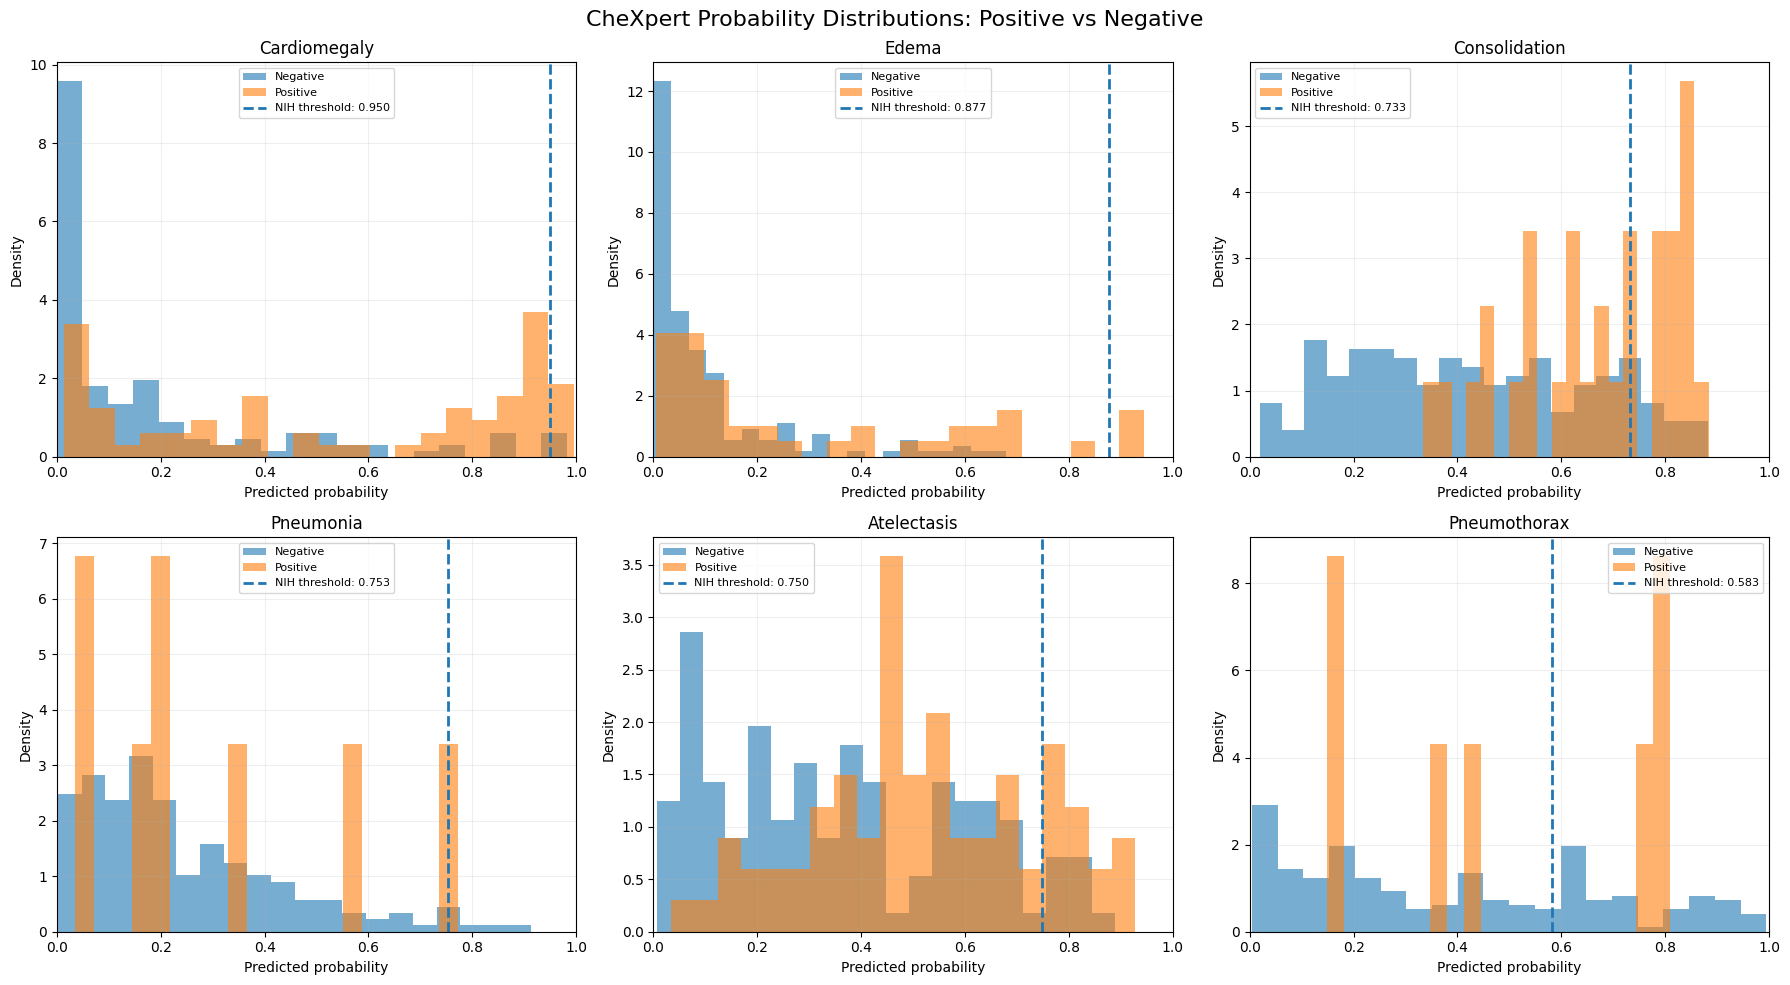

In [19]:

import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, label in enumerate(LABELS):

    ax = axes[i]

    positive = chex_predictions.loc[
        chex_predictions[f"true_{label}"] == 1,
        f"prob_{label}"
    ].dropna()

    negative = chex_predictions.loc[
        chex_predictions[f"true_{label}"] == 0,
        f"prob_{label}"
    ].dropna()

    threshold = threshold_map[label]

    ax.hist(
        negative,
        bins=20,
        alpha=0.6,
        density=True,
        label="Negative",
    )

    ax.hist(
        positive,
        bins=20,
        alpha=0.6,
        density=True,
        label="Positive",
    )

    ax.axvline(
        threshold,
        linestyle="--",
        linewidth=2,
        label=f"NIH threshold: {threshold:.3f}"
    )

    ax.set_title(label)
    ax.set_xlabel("Predicted probability")
    ax.set_ylabel("Density")
    ax.set_xlim(0, 1)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)

plt.suptitle(
    "CheXpert Probability Distributions: Positive vs Negative",
    fontsize=16
)

plt.tight_layout()
plt.show()


NIH VS CHEXPERT RAW IMAGE STATISTICS


,Count,Mean_Width,Mean_Height,Mean_Aspect_Ratio,Mean_Brightness,Mean_Contrast,Median_Pixel,Mean_P01,Mean_P99
Dataset,,,,,,,,,
CheXpert,202,380.163,320.406,1.187,129.085007,73.839996,129.792007,3.074,252.401001
NIH,202,1024.000,1024.000,1.000,121.371002,56.528000,126.723000,3.713,211.360992



Image statistics collected: 404


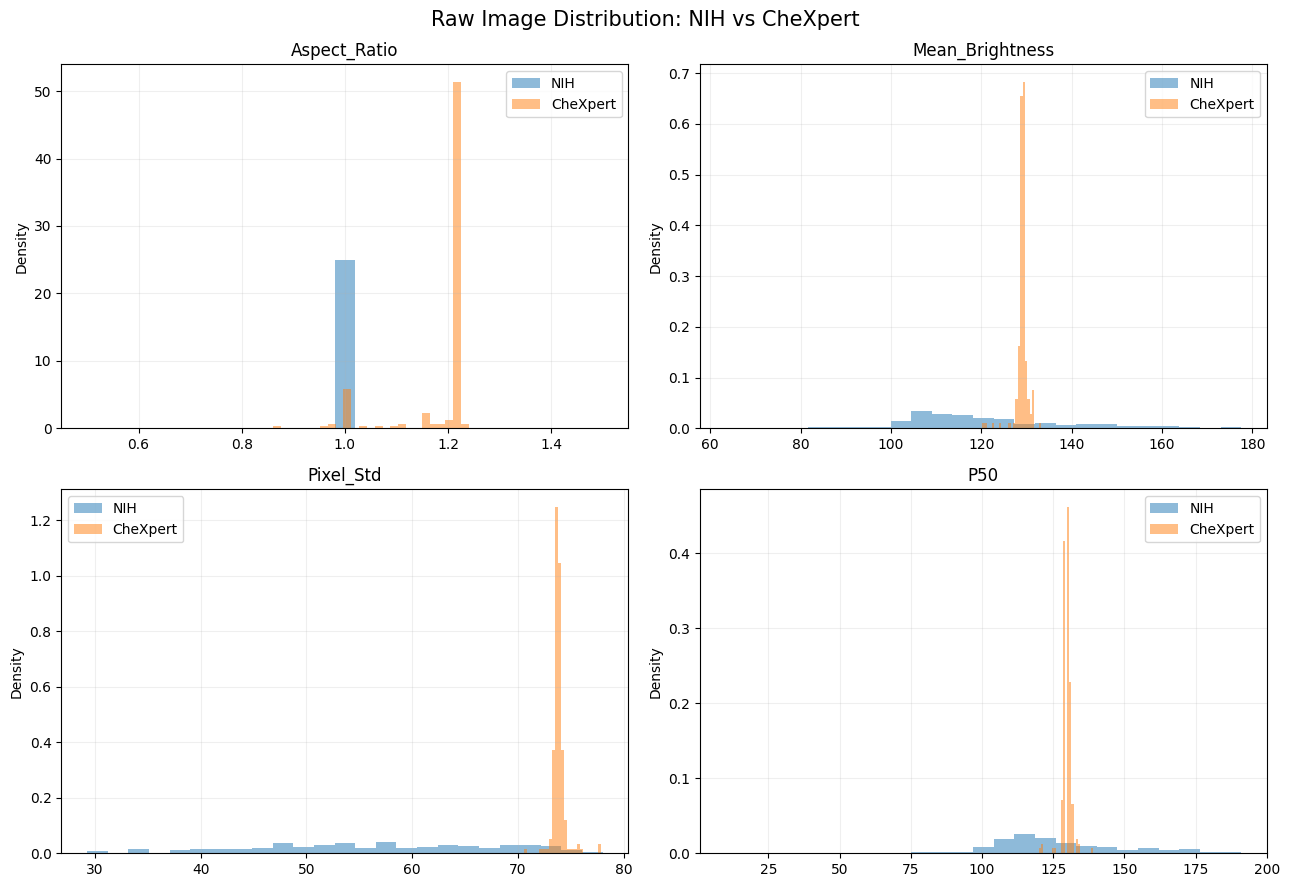

In [20]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image

# Load NIH test manifest
nih_manifest = pd.read_csv(MANIFEST)

nih_test_df = nih_manifest[
    nih_manifest["split"] == "test"
].sample(
    n=202,
    random_state=42
).reset_index(drop=True)

chex_sample_df = chexpert_eval.reset_index(drop=True)

def extract_image_statistics(image_path, dataset_name):

    with Image.open(image_path) as image:
        image = image.convert("L")

        width, height = image.size
        pixels = np.asarray(image, dtype=np.float32)

    return {
        "Dataset": dataset_name,
        "Width": width,
        "Height": height,
        "Aspect_Ratio": width / height,
        "Mean_Brightness": pixels.mean(),
        "Pixel_Std": pixels.std(),
        "P01": np.percentile(pixels, 1),
        "P25": np.percentile(pixels, 25),
        "P50": np.percentile(pixels, 50),
        "P75": np.percentile(pixels, 75),
        "P99": np.percentile(pixels, 99)
    }

statistics = []

for _, row in nih_test_df.iterrows():
    statistics.append(
        extract_image_statistics(
            row["image_path"],
            "NIH"
        )
    )

for _, row in chex_sample_df.iterrows():
    statistics.append(
        extract_image_statistics(
            row["image_path"],
            "CheXpert"
        )
    )

image_stats_df = pd.DataFrame(statistics)

summary = image_stats_df.groupby("Dataset").agg(
    Count=("Width", "count"),
    Mean_Width=("Width", "mean"),
    Mean_Height=("Height", "mean"),
    Mean_Aspect_Ratio=("Aspect_Ratio", "mean"),
    Mean_Brightness=("Mean_Brightness", "mean"),
    Mean_Contrast=("Pixel_Std", "mean"),
    Median_Pixel=("P50", "mean"),
    Mean_P01=("P01", "mean"),
    Mean_P99=("P99", "mean")
).round(3)

print("NIH VS CHEXPERT RAW IMAGE STATISTICS")
display(summary)

print("\nImage statistics collected:", len(image_stats_df))

# Visual comparison
features = [
    "Aspect_Ratio",
    "Mean_Brightness",
    "Pixel_Std",
    "P50"
]

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for ax, feature in zip(axes.flatten(), features):

    for dataset_name in ["NIH", "CheXpert"]:

        values = image_stats_df.loc[
            image_stats_df["Dataset"] == dataset_name,
            feature
        ]

        ax.hist(
            values,
            bins=25,
            alpha=0.5,
            density=True,
            label=dataset_name
        )

    ax.set_title(feature)
    ax.set_ylabel("Density")
    ax.legend()
    ax.grid(alpha=0.2)

plt.suptitle(
    "Raw Image Distribution: NIH vs CheXpert",
    fontsize=15
)

plt.tight_layout()
plt.show()


In [21]:

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

from PIL import Image, ImageOps
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import roc_auc_score, average_precision_score

from torchvision import transforms

IMAGE_SIZE = 224
BATCH_SIZE = 32

# Experiment A: Existing direct resize
direct_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Experiment B: Preserve aspect ratio, then pad
class AspectPreservingTransform:

    def __init__(self, size=224):
        self.size = size
        self.normalize = transforms.Normalize(
            mean=[0.485, 0.456, 0.406],
            std=[0.229, 0.224, 0.225]
        )

    def __call__(self, image):
        image = image.convert("RGB")

        # Use image median as padding color
        gray = np.asarray(
            image.convert("L"),
            dtype=np.uint8
        )
        fill_value = int(np.median(gray))

        image = ImageOps.pad(
            image,
            (self.size, self.size),
            method=Image.Resampling.BILINEAR,
            color=(fill_value, fill_value, fill_value),
            centering=(0.5, 0.5)
        )

        return self.normalize(
            transforms.ToTensor()(image)
        )

aspect_transform = AspectPreservingTransform(IMAGE_SIZE)


class CheXpertPreprocessingDataset(Dataset):

    def __init__(self, dataframe, transform):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]

        with Image.open(row["image_path"]) as image:
            image = image.convert("RGB")
            image = self.transform(image)

        targets = torch.tensor(
            row[
                [f"eval_{label}" for label in LABELS]
            ].to_numpy(dtype=np.float32),
            dtype=torch.float32
        )

        return image, targets


def run_preprocessing_inference(transform):

    dataset = CheXpertPreprocessingDataset(
        chexpert_eval,
        transform
    )

    loader = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0,
        pin_memory=torch.cuda.is_available()
    )

    probabilities = []
    targets_list = []

    model.eval()

    with torch.inference_mode():

        for batch_idx, (images, targets) in enumerate(loader):

            images = images.to(DEVICE, non_blocking=True)

            with torch.autocast(
                device_type=DEVICE.type,
                dtype=torch.float16,
                enabled=DEVICE.type == "cuda"
            ):
                logits = model(images)

            probabilities.append(
                torch.sigmoid(logits).float().cpu().numpy()
            )

            targets_list.append(targets.numpy())

            print(
                f"Processed {batch_idx + 1}/{len(loader)} batches"
            )

    return (
        np.concatenate(targets_list),
        np.concatenate(probabilities)
    )


print("EXPERIMENT A: DIRECT RESIZE")
y_direct, p_direct = run_preprocessing_inference(
    direct_transform
)

print("\nEXPERIMENT B: ASPECT-PRESERVING RESIZE")
y_aspect, p_aspect = run_preprocessing_inference(
    aspect_transform
)

assert np.array_equal(y_direct, y_aspect, equal_nan=True)

comparison = []

for i, label in enumerate(LABELS):

    valid = np.isfinite(y_direct[:, i])
    y_true = y_direct[valid, i].astype(int)

    row = {"Disease": label}

    for name, probabilities in [
        ("Direct", p_direct),
        ("Aspect_Preserved", p_aspect)
    ]:

        scores = probabilities[valid, i]

        if len(np.unique(y_true)) == 2:
            auc = roc_auc_score(y_true, scores)
            ap = average_precision_score(y_true, scores)
        else:
            auc = np.nan
            ap = np.nan

        row[f"{name}_AUROC"] = auc
        row[f"{name}_AUPRC"] = ap

    row["AUROC_Difference"] = (
        row["Aspect_Preserved_AUROC"] -
        row["Direct_AUROC"]
    )

    comparison.append(row)

comparison_df = pd.DataFrame(comparison)

comparison_df.to_csv(
    "/kaggle/working/chexpert_preprocessing_comparison.csv",
    index=False
)

print("\nPREPROCESSING COMPARISON")
display(comparison_df.round(4))

print(
    "\nMean direct AUROC:",
    round(comparison_df["Direct_AUROC"].mean(), 4)
)

print(
    "Mean aspect-preserved AUROC:",
    round(comparison_df["Aspect_Preserved_AUROC"].mean(), 4)
)

print("\nComparison saved successfully.")


EXPERIMENT A: DIRECT RESIZE
Processed 1/7 batches
Processed 2/7 batches
Processed 3/7 batches
Processed 4/7 batches
Processed 5/7 batches
Processed 6/7 batches
Processed 7/7 batches

EXPERIMENT B: ASPECT-PRESERVING RESIZE
Processed 1/7 batches
Processed 2/7 batches
Processed 3/7 batches
Processed 4/7 batches
Processed 5/7 batches
Processed 6/7 batches
Processed 7/7 batches

PREPROCESSING COMPARISON


,Disease,Direct_AUROC,Direct_AUPRC,Aspect_Preserved_AUROC,Aspect_Preserved_AUPRC,AUROC_Difference
0,Cardiomegaly,0.8028,0.6640,0.8038,0.6692,0.0009
1,Edema,0.7371,0.5285,0.7312,0.5062,-0.0059
2,Consolidation,0.8028,0.4261,0.7891,0.4113,-0.0137
3,Pneumonia,0.5348,0.0769,0.5470,0.0620,0.0122
4,Atelectasis,0.6925,0.5494,0.7097,0.5582,0.0172
5,Pneumothorax,0.6132,0.0586,0.5121,0.0432,-0.1011



Mean direct AUROC: 0.6972
Mean aspect-preserved AUROC: 0.6821

Comparison saved successfully.


In [22]:

import numpy as np
import pandas as pd

from sklearn.metrics import roc_auc_score, average_precision_score

N_BOOTSTRAPS = 1000
RANDOM_STATE = 42

rng = np.random.default_rng(RANDOM_STATE)

bootstrap_results = []

for i, label in enumerate(LABELS):

    y = y_direct[:, i]

    positive_idx = np.where(y == 1)[0]
    negative_idx = np.where(y == 0)[0]

    if len(positive_idx) < 2 or len(negative_idx) < 2:
        continue

    direct_auc_samples = []
    aspect_auc_samples = []
    delta_samples = []

    for _ in range(N_BOOTSTRAPS):

        sampled_positive = rng.choice(
            positive_idx,
            size=len(positive_idx),
            replace=True
        )

        sampled_negative = rng.choice(
            negative_idx,
            size=len(negative_idx),
            replace=True
        )

        sampled_idx = np.concatenate([
            sampled_positive,
            sampled_negative
        ])

        y_sample = y[sampled_idx].astype(int)

        direct_auc = roc_auc_score(
            y_sample,
            p_direct[sampled_idx, i]
        )

        aspect_auc = roc_auc_score(
            y_sample,
            p_aspect[sampled_idx, i]
        )

        direct_auc_samples.append(direct_auc)
        aspect_auc_samples.append(aspect_auc)
        delta_samples.append(aspect_auc - direct_auc)

    direct_auc_samples = np.array(direct_auc_samples)
    aspect_auc_samples = np.array(aspect_auc_samples)
    delta_samples = np.array(delta_samples)

    bootstrap_results.append({

        "Disease": label,

        "Direct_AUROC": roc_auc_score(
            y,
            p_direct[:, i]
        ),

        "Direct_CI_Lower": np.percentile(
            direct_auc_samples, 2.5
        ),

        "Direct_CI_Upper": np.percentile(
            direct_auc_samples, 97.5
        ),

        "Aspect_AUROC": roc_auc_score(
            y,
            p_aspect[:, i]
        ),

        "Aspect_CI_Lower": np.percentile(
            aspect_auc_samples, 2.5
        ),

        "Aspect_CI_Upper": np.percentile(
            aspect_auc_samples, 97.5
        ),

        "AUROC_Difference": np.mean(delta_samples),

        "Difference_CI_Lower": np.percentile(
            delta_samples, 2.5
        ),

        "Difference_CI_Upper": np.percentile(
            delta_samples, 97.5
        ),

        "Positive_Count": len(positive_idx),
        "Negative_Count": len(negative_idx)
    })

bootstrap_df = pd.DataFrame(bootstrap_results)

BOOTSTRAP_PATH = (
    "/kaggle/working/chexpert_preprocessing_bootstrap.csv"
)

bootstrap_df.to_csv(
    BOOTSTRAP_PATH,
    index=False
)

print("STRATIFIED BOOTSTRAP RESULTS")
display(bootstrap_df.round(4))

print("\nSaved:", BOOTSTRAP_PATH)
print("Bootstrap iterations:", N_BOOTSTRAPS)


STRATIFIED BOOTSTRAP RESULTS


,Disease,Direct_AUROC,Direct_CI_Lower,Direct_CI_Upper,Aspect_AUROC,Aspect_CI_Lower,Aspect_CI_Upper,AUROC_Difference,Difference_CI_Lower,Difference_CI_Upper,Positive_Count,Negative_Count
0,Cardiomegaly,0.8028,0.7390,0.8649,0.8038,0.7419,0.8666,0.0006,-0.0181,0.0204,66,136
1,Edema,0.7371,0.6503,0.8134,0.7312,0.6385,0.8107,-0.0059,-0.0389,0.0258,42,160
2,Consolidation,0.8028,0.7312,0.8717,0.7891,0.7186,0.8550,-0.0133,-0.0437,0.0182,32,170
3,Pneumonia,0.5348,0.3021,0.7558,0.5470,0.3196,0.7545,0.0114,-0.0445,0.0832,8,194
4,Atelectasis,0.6925,0.6216,0.7620,0.7097,0.6413,0.7789,0.0172,-0.0098,0.0463,75,127
5,Pneumothorax,0.6132,0.4278,0.8015,0.5121,0.3135,0.7128,-0.0990,-0.1766,-0.0264,7,195



Saved: /kaggle/working/chexpert_preprocessing_bootstrap.csv
Bootstrap iterations: 1000


In [23]:

import numpy as np
import pandas as pd

integrity_results = []

for i, label in enumerate(LABELS):

    y = y_chex[:, i]
    probabilities = p_chex[:, i]

    valid = np.isfinite(y)

    integrity_results.append({
        "Disease": label,
        "Total_Images": len(y),
        "Valid_Labels": int(valid.sum()),
        "Missing_Labels": int((~valid).sum()),
        "Positive": int((y[valid] == 1).sum()),
        "Negative": int((y[valid] == 0).sum()),
        "Invalid_Label_Values": int(
            (~np.isin(y[valid], [0, 1])).sum()
        ),
        "Missing_Probabilities": int(
            (~np.isfinite(probabilities)).sum()
        ),
        "Min_Probability": float(
            np.nanmin(probabilities)
        ),
        "Max_Probability": float(
            np.nanmax(probabilities)
        )
    })

integrity_df = pd.DataFrame(integrity_results)

print("CHEXPERT DATA INTEGRITY AUDIT")
display(integrity_df)

print("\nOriginal manifest label counts:")
for label in LABELS:
    values = chexpert_eval[f"eval_{label}"]
    print(
        label,
        "| Valid:", int(values.notna().sum()),
        "| Positive:", int((values == 1).sum()),
        "| Negative:", int((values == 0).sum())
    )

print("\nPrediction and manifest alignment:")
print("Same number of records:", len(y_chex) == len(chexpert_eval))
print("Prediction shape:", y_chex.shape)
print("Expected shape:", (len(chexpert_eval), len(LABELS)))


CHEXPERT DATA INTEGRITY AUDIT


,Disease,Total_Images,Valid_Labels,Missing_Labels,Positive,Negative,Invalid_Label_Values,Missing_Probabilities,Min_Probability,Max_Probability
0,Cardiomegaly,202,202,0,66,136,0,0,0.000023,0.995605
1,Edema,202,202,0,42,160,0,0,0.000205,0.944824
2,Consolidation,202,202,0,32,170,0,0,0.018875,0.883789
3,Pneumonia,202,202,0,8,194,0,0,0.001889,0.914062
4,Atelectasis,202,202,0,75,127,0,0,0.006462,0.927734
5,Pneumothorax,202,202,0,7,195,0,0,0.004314,0.994629



Original manifest label counts:
Cardiomegaly | Valid: 202 | Positive: 66 | Negative: 136
Edema | Valid: 202 | Positive: 42 | Negative: 160
Consolidation | Valid: 202 | Positive: 32 | Negative: 170
Pneumonia | Valid: 202 | Positive: 8 | Negative: 194
Atelectasis | Valid: 202 | Positive: 75 | Negative: 127
Pneumothorax | Valid: 202 | Positive: 7 | Negative: 195

Prediction and manifest alignment:
Same number of records: True
Prediction shape: (202, 6)
Expected shape: (202, 6)


In [24]:


import numpy as np
import pandas as pd

error_records = []

for i, label in enumerate(LABELS):

    y_true = y_chex[:, i].astype(int)
    y_prob = p_chex[:, i]
    threshold = threshold_map[label]

    y_pred = (y_prob >= threshold).astype(int)

    for j in range(len(y_true)):

        if y_true[j] == 1 and y_pred[j] == 1:
            error_type = "TP"

        elif y_true[j] == 0 and y_pred[j] == 0:
            error_type = "TN"

        elif y_true[j] == 0 and y_pred[j] == 1:
            error_type = "FP"

        else:
            error_type = "FN"

        error_records.append({
            "image_path": chexpert_eval.iloc[j]["image_path"],
            "patient_id": chexpert_eval.iloc[j]["Path"].split("/")[1],
            "Disease": label,
            "True_Label": int(y_true[j]),
            "Predicted_Label": int(y_pred[j]),
            "Probability": float(y_prob[j]),
            "Threshold": threshold,
            "Error_Type": error_type
        })

error_df = pd.DataFrame(error_records)

ERROR_PATH = (
    "/kaggle/working/chexpert_error_analysis.csv"
)

error_df.to_csv(ERROR_PATH, index=False)

error_summary = (
    error_df.groupby(["Disease", "Error_Type"])
    .size()
    .unstack(fill_value=0)
    .reset_index()
)

for column in ["TP", "TN", "FP", "FN"]:
    if column not in error_summary.columns:
        error_summary[column] = 0

error_summary["Total_Errors"] = (
    error_summary["FP"] + error_summary["FN"]
)

print("CHEXPERT ERROR ANALYSIS")
display(error_summary)

print("\nTotal prediction records:", len(error_df))
print("Total false positives:", int((error_df["Error_Type"] == "FP").sum()))
print("Total false negatives:", int((error_df["Error_Type"] == "FN").sum()))
print("Saved:", ERROR_PATH)


CHEXPERT ERROR ANALYSIS


Error_Type,Disease,FN,FP,TN,TP,Total_Errors
0,Atelectasis,60,10,117,15,70
1,Cardiomegaly,60,4,132,6,64
2,Consolidation,18,17,153,14,35
3,Edema,39,0,160,3,39
4,Pneumonia,7,6,188,1,13
5,Pneumothorax,4,60,135,3,64



Total prediction records: 1212
Total false positives: 97
Total false negatives: 188
Saved: /kaggle/working/chexpert_error_analysis.csv


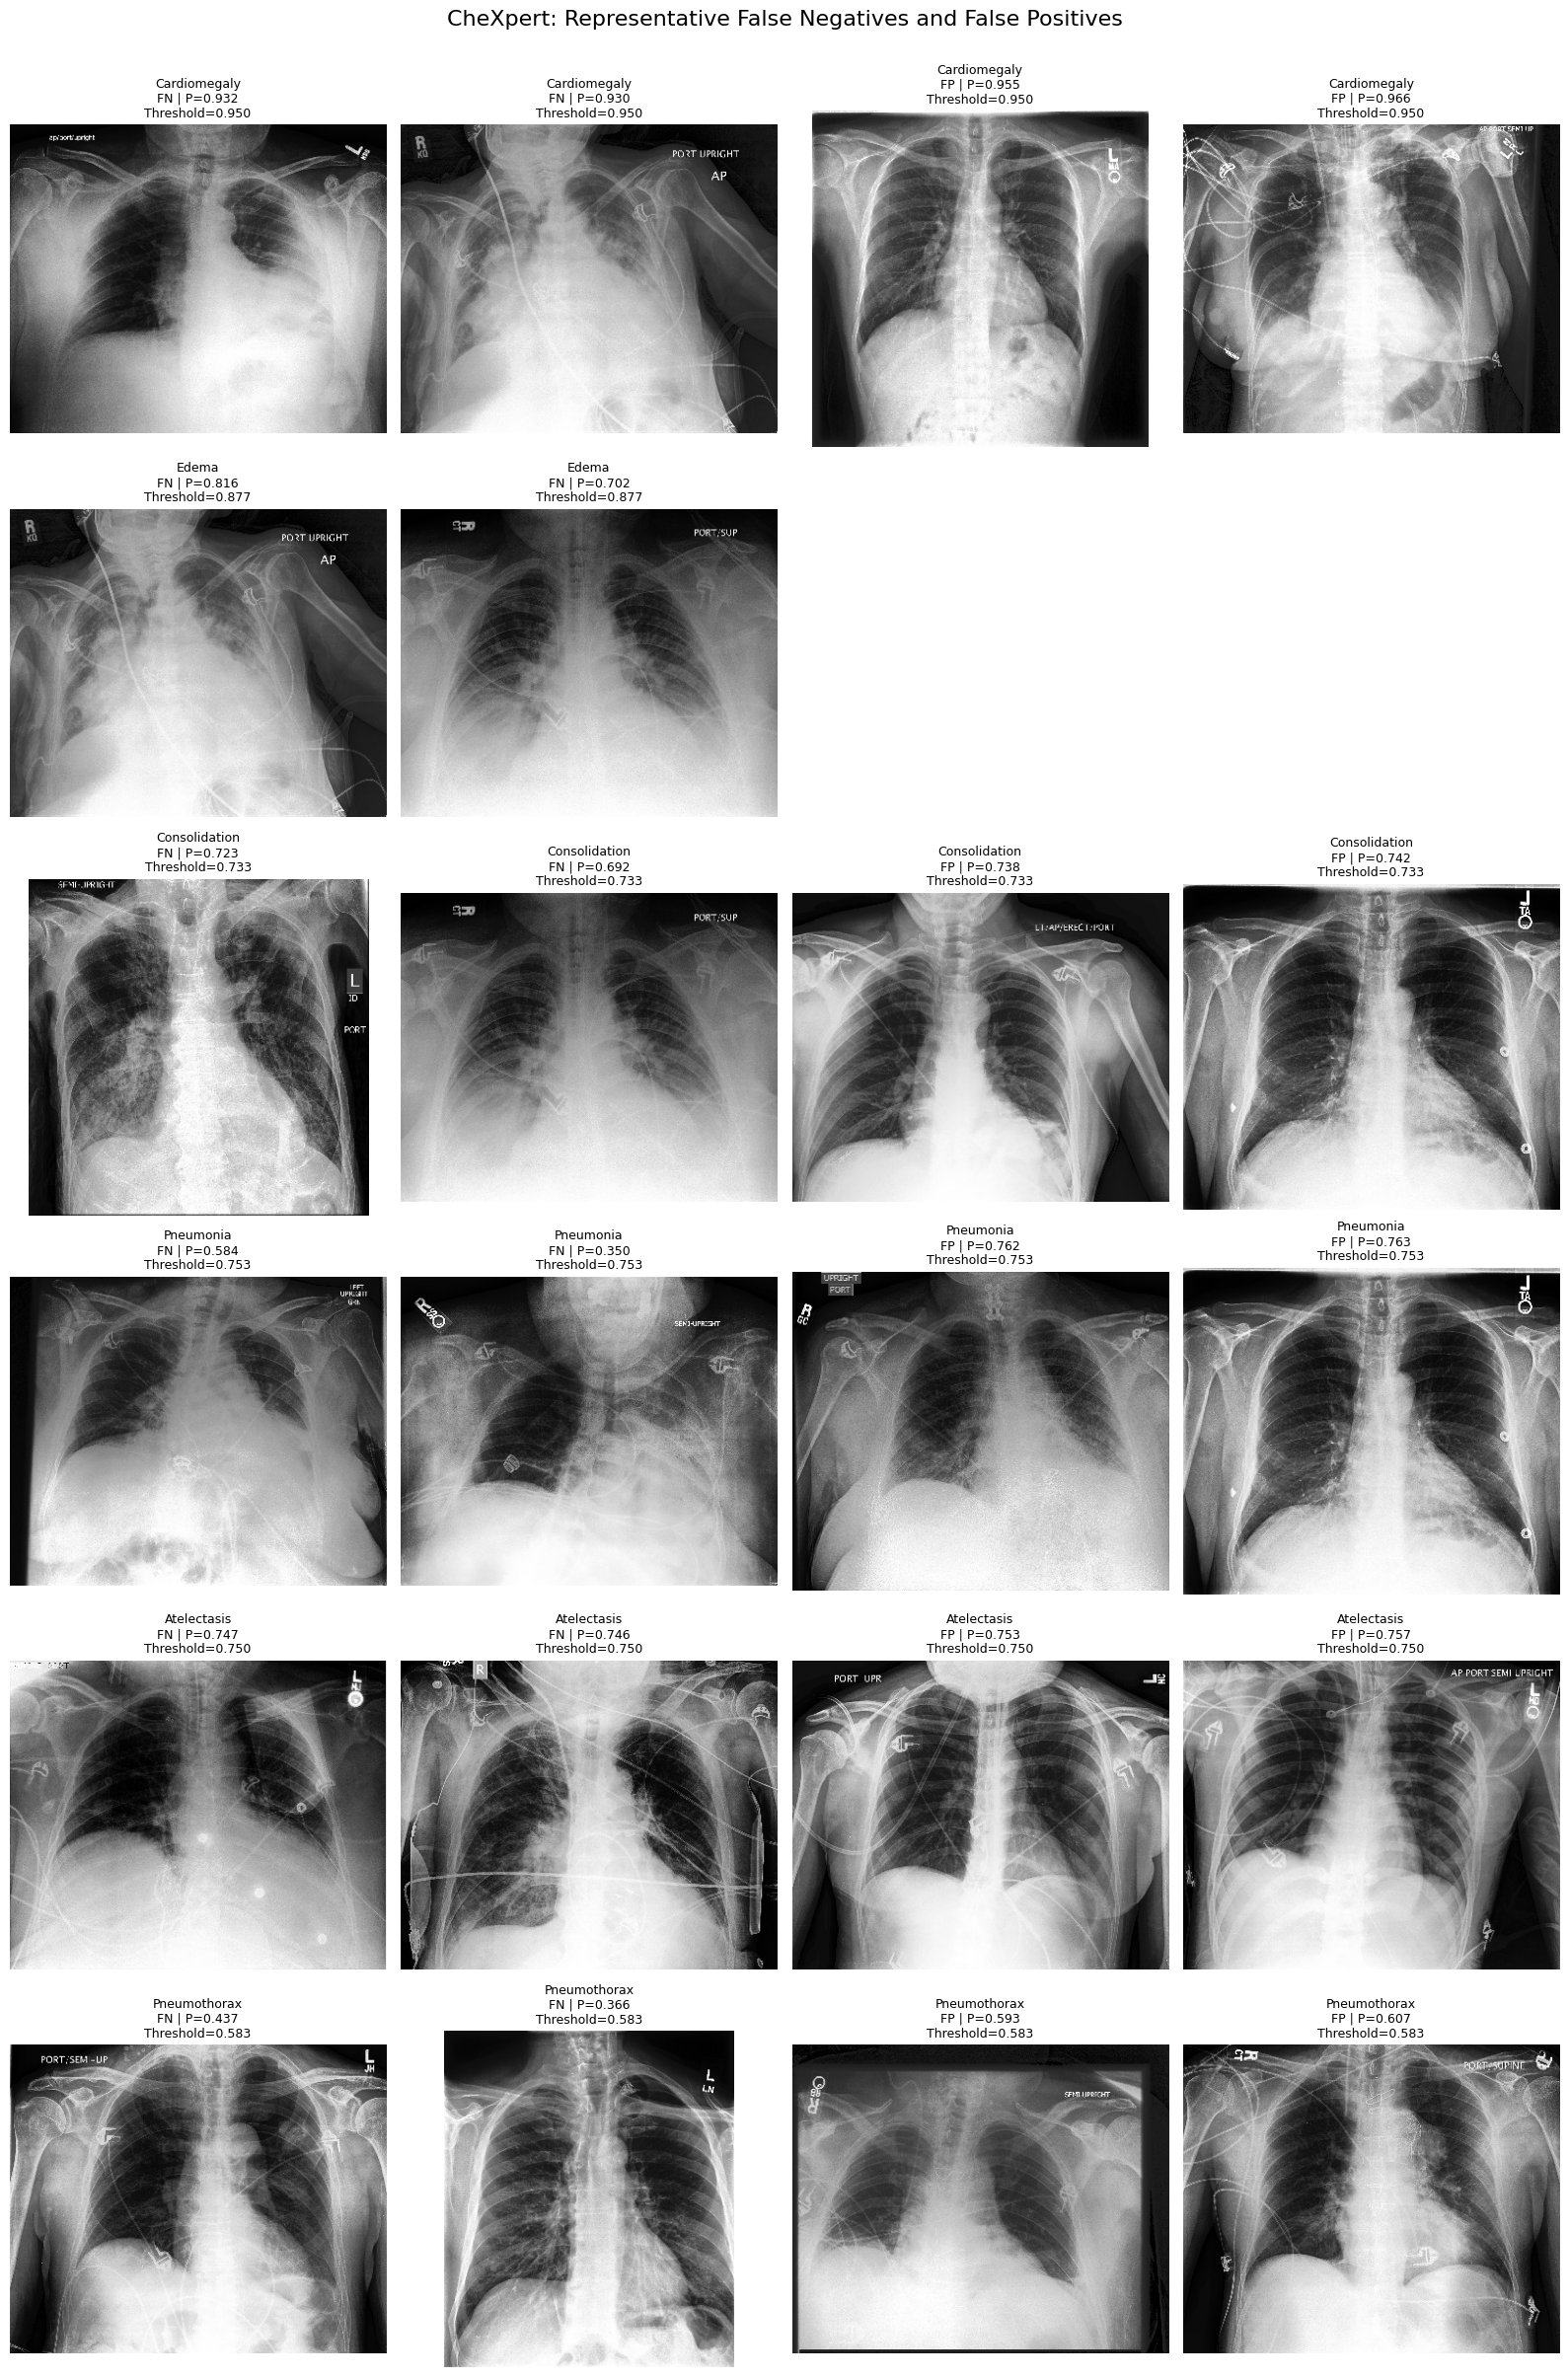

In [25]:

import matplotlib.pyplot as plt
import numpy as np

from PIL import Image

fig, axes = plt.subplots(
    len(LABELS),
    4,
    figsize=(16, 24)
)

for i, label in enumerate(LABELS):

    disease_errors = error_df[
        error_df["Disease"] == label
    ]

    threshold = threshold_map[label]

    # False negatives closest to threshold
    fn_cases = disease_errors[
        disease_errors["Error_Type"] == "FN"
    ].copy()

    fn_cases["Distance"] = (
        threshold - fn_cases["Probability"]
    )

    fn_cases = fn_cases.nsmallest(2, "Distance")

    # False positives closest to threshold
    fp_cases = disease_errors[
        disease_errors["Error_Type"] == "FP"
    ].copy()

    fp_cases["Distance"] = (
        fp_cases["Probability"] - threshold
    )

    fp_cases = fp_cases.nsmallest(2, "Distance")

    selected_cases = [
        (fn_cases, "FN"),
        (fp_cases, "FP")
    ]

    column = 0

    for cases, error_type in selected_cases:

        for _, row in cases.iterrows():

            ax = axes[i, column]

            with Image.open(row["image_path"]) as image:
                ax.imshow(image.convert("L"), cmap="gray")

            ax.set_title(
                f"{label}\n"
                f"{error_type} | "
                f"P={row['Probability']:.3f}\n"
                f"Threshold={threshold:.3f}",
                fontsize=9
            )

            ax.axis("off")
            column += 1

    while column < 4:
        axes[i, column].axis("off")
        column += 1

plt.suptitle(
    "CheXpert: Representative False Negatives and False Positives",
    fontsize=16,
    y=1.002
)

plt.tight_layout()
plt.show()


In [26]:

import numpy as np
import pandas as pd

# Prepare image-level metadata
metadata = chexpert_eval[
    ["image_path", "Sex", "Age", "AP/PA", "Support Devices"]
].copy()

metadata["Age"] = pd.to_numeric(
    metadata["Age"],
    errors="coerce"
)

# Preserve original support-device uncertainty
metadata["Support_Device_Status"] = metadata[
    "Support Devices"
].map({
    1.0: "Present",
    0.0: "Absent",
    -1.0: "Uncertain"
}).fillna("Unmentioned")

# Attach metadata to disease-level error records
subgroup_errors = error_df.merge(
    metadata,
    on="image_path",
    how="left",
    validate="many_to_one"
)

# Create age groups
subgroup_errors["Age_Group"] = pd.cut(
    subgroup_errors["Age"],
    bins=[0, 40, 60, 80, 120],
    labels=["18-40", "41-60", "61-80", "81+"],
    include_lowest=True
)

def calculate_error_summary(data, group_column):

    result = (
        data.groupby(
            [group_column, "Error_Type"],
            observed=True
        )
        .size()
        .unstack(fill_value=0)
    )

    for col in ["TP", "TN", "FP", "FN"]:
        if col not in result.columns:
            result[col] = 0

    result["Total"] = result[
        ["TP", "TN", "FP", "FN"]
    ].sum(axis=1)

    result["Error_Count"] = (
        result["FP"] + result["FN"]
    )

    result["Error_Rate"] = (
        result["Error_Count"] / result["Total"]
    )

    return result.reset_index()


print("ERROR ANALYSIS BY AP/PA")
display(
    calculate_error_summary(
        subgroup_errors,
        "AP/PA"
    ).round(4)
)

print("\nERROR ANALYSIS BY SUPPORT DEVICES")
display(
    calculate_error_summary(
        subgroup_errors,
        "Support_Device_Status"
    ).round(4)
)

print("\nERROR ANALYSIS BY AGE GROUP")
display(
    calculate_error_summary(
        subgroup_errors,
        "Age_Group"
    ).round(4)
)

print("\nERROR ANALYSIS BY SEX")
display(
    calculate_error_summary(
        subgroup_errors,
        "Sex"
    ).round(4)
)

# Save detailed subgroup analysis
subgroup_errors.to_csv(
    "/kaggle/working/chexpert_subgroup_error_analysis.csv",
    index=False
)

print("\nSubgroup analysis saved successfully.")


ERROR ANALYSIS BY AP/PA


Error_Type,AP/PA,FN,FP,TN,TP,Total,Error_Count,Error_Rate
0,AP,180,90,702,42,1014,270,0.2663
1,PA,8,7,183,0,198,15,0.0758



ERROR ANALYSIS BY SUPPORT DEVICES


Error_Type,Support_Device_Status,FN,FP,TN,TP,Total,Error_Count,Error_Rate
0,Absent,87,37,472,22,618,124,0.2006
1,Present,101,60,413,20,594,161,0.2710



ERROR ANALYSIS BY AGE GROUP


Error_Type,Age_Group,FN,FP,TN,TP,Total,Error_Count,Error_Rate
0,18-40,16,6,143,9,174,22,0.1264
1,41-60,55,29,292,14,390,84,0.2154
2,61-80,72,51,340,11,474,123,0.2595
3,81+,45,11,110,8,174,56,0.3218



ERROR ANALYSIS BY SEX


Error_Type,Sex,FN,FP,TN,TP,Total,Error_Count,Error_Rate
0,Female,87,44,410,23,564,131,0.2323
1,Male,101,53,475,19,648,154,0.2377



Subgroup analysis saved successfully.


In [27]:

import numpy as np
import pandas as pd

def subgroup_disease_metrics(data, subgroup_column):

    results = []

    for label in LABELS:

        disease_data = data[
            data["Disease"] == label
        ]

        for subgroup, group in disease_data.groupby(
            subgroup_column,
            dropna=False,
            observed=True
        ):

            y_true = group["True_Label"].to_numpy(dtype=int)
            y_pred = group["Predicted_Label"].to_numpy(dtype=int)

            tp = int(((y_true == 1) & (y_pred == 1)).sum())
            fp = int(((y_true == 0) & (y_pred == 1)).sum())
            tn = int(((y_true == 0) & (y_pred == 0)).sum())
            fn = int(((y_true == 1) & (y_pred == 0)).sum())

            positives = tp + fn
            negatives = tn + fp
            total = len(group)

            sensitivity = (
                tp / positives if positives else np.nan
            )

            specificity = (
                tn / negatives if negatives else np.nan
            )

            precision = (
                tp / (tp + fp) if (tp + fp) else 0
            )

            f1 = (
                2 * precision * sensitivity /
                (precision + sensitivity)
                if np.isfinite(sensitivity)
                and (precision + sensitivity) > 0
                else 0
            )

            results.append({
                "Disease": label,
                "Subgroup": str(subgroup),
                "Images": total,
                "Positive": positives,
                "Negative": negatives,
                "TP": tp,
                "FP": fp,
                "TN": tn,
                "FN": fn,
                "Sensitivity": sensitivity,
                "Specificity": specificity,
                "Precision": precision,
                "F1": f1,
                "Error_Rate": (fp + fn) / total if total else np.nan
            })

    return pd.DataFrame(results)


subgroup_columns = [
    "AP/PA",
    "Support_Device_Status",
    "Age_Group",
    "Sex"
]

subgroup_results = {}

for column in subgroup_columns:

    result = subgroup_disease_metrics(
        subgroup_errors,
        column
    )

    subgroup_results[column] = result

    print(f"\nDISEASE-WISE RESULTS BY {column.upper()}")
    display(
        result.round(4)
    )

# Save all subgroup results in one CSV
combined_results = pd.concat(
    [
        df.assign(Subgroup_Type=column)
        for column, df in subgroup_results.items()
    ],
    ignore_index=True
)

OUTPUT_PATH = (
    "/kaggle/working/chexpert_disease_wise_subgroup_metrics.csv"
)

combined_results.to_csv(
    OUTPUT_PATH,
    index=False
)

print("\nSaved:", OUTPUT_PATH)
print("Total subgroup metric records:", len(combined_results))



DISEASE-WISE RESULTS BY AP/PA


,Disease,Subgroup,Images,Positive,Negative,TP,FP,TN,FN,Sensitivity,Specificity,Precision,F1,Error_Rate
0,Cardiomegaly,AP,169,65,104,6,3,101,59,0.0923,0.9712,0.6667,0.1622,0.3669
1,Cardiomegaly,PA,33,1,32,0,1,31,1,0.0000,0.9688,0.0000,0.0000,0.0606
2,Edema,AP,169,41,128,3,0,128,38,0.0732,1.0000,1.0000,0.1364,0.2249
3,Edema,PA,33,1,32,0,0,32,1,0.0000,1.0000,0.0000,0.0000,0.0303
4,Consolidation,AP,169,32,137,14,16,121,18,0.4375,0.8832,0.4667,0.4516,0.2012
5,Consolidation,PA,33,0,33,0,1,32,0,NaN,0.9697,0.0000,0.0000,0.0303
6,Pneumonia,AP,169,8,161,1,4,157,7,0.1250,0.9752,0.2000,0.1538,0.0651
7,Pneumonia,PA,33,0,33,0,2,31,0,NaN,0.9394,0.0000,0.0000,0.0606
8,Atelectasis,AP,169,71,98,15,10,88,56,0.2113,0.8980,0.6000,0.3125,0.3905
9,Atelectasis,PA,33,4,29,0,0,29,4,0.0000,1.0000,0.0000,0.0000,0.1212



DISEASE-WISE RESULTS BY SUPPORT_DEVICE_STATUS


,Disease,Subgroup,Images,Positive,Negative,TP,FP,TN,FN,Sensitivity,Specificity,Precision,F1,Error_Rate
0,Cardiomegaly,Absent,103,32,71,5,2,69,27,0.1562,0.9718,0.7143,0.2564,0.2816
1,Cardiomegaly,Present,99,34,65,1,2,63,33,0.0294,0.9692,0.3333,0.0541,0.3535
2,Edema,Absent,103,18,85,1,0,85,17,0.0556,1.0000,1.0000,0.1053,0.1650
3,Edema,Present,99,24,75,2,0,75,22,0.0833,1.0000,1.0000,0.1538,0.2222
4,Consolidation,Absent,103,16,87,7,7,80,9,0.4375,0.9195,0.5000,0.4667,0.1553
5,Consolidation,Present,99,16,83,7,10,73,9,0.4375,0.8795,0.4118,0.4242,0.1919
6,Pneumonia,Absent,103,5,98,1,4,94,4,0.2000,0.9592,0.2000,0.2000,0.0777
7,Pneumonia,Present,99,3,96,0,2,94,3,0.0000,0.9792,0.0000,0.0000,0.0505
8,Atelectasis,Absent,103,35,68,8,3,65,27,0.2286,0.9559,0.7273,0.3478,0.2913
9,Atelectasis,Present,99,40,59,7,7,52,33,0.1750,0.8814,0.5000,0.2593,0.4040



DISEASE-WISE RESULTS BY AGE_GROUP


,Disease,Subgroup,Images,Positive,Negative,TP,FP,TN,FN,Sensitivity,Specificity,Precision,F1,Error_Rate
0,Cardiomegaly,18-40,29,8,21,1,0,21,7,0.1250,1.0000,1.0000,0.2222,0.2414
1,Cardiomegaly,41-60,65,19,46,2,2,44,17,0.1053,0.9565,0.5000,0.1739,0.2923
2,Cardiomegaly,61-80,79,26,53,2,1,52,24,0.0769,0.9811,0.6667,0.1379,0.3165
3,Cardiomegaly,81+,29,13,16,1,1,15,12,0.0769,0.9375,0.5000,0.1333,0.4483
4,Edema,18-40,29,6,23,1,0,23,5,0.1667,1.0000,1.0000,0.2857,0.1724
5,Edema,41-60,65,10,55,1,0,55,9,0.1000,1.0000,1.0000,0.1818,0.1385
6,Edema,61-80,79,16,63,1,0,63,15,0.0625,1.0000,1.0000,0.1176,0.1899
7,Edema,81+,29,10,19,0,0,19,10,0.0000,1.0000,0.0000,0.0000,0.3448
8,Consolidation,18-40,29,5,24,3,1,23,2,0.6000,0.9583,0.7500,0.6667,0.1034
9,Consolidation,41-60,65,10,55,4,6,49,6,0.4000,0.8909,0.4000,0.4000,0.1846



DISEASE-WISE RESULTS BY SEX


,Disease,Subgroup,Images,Positive,Negative,TP,FP,TN,FN,Sensitivity,Specificity,Precision,F1,Error_Rate
0,Cardiomegaly,Female,94,30,64,4,3,61,26,0.1333,0.9531,0.5714,0.2162,0.3085
1,Cardiomegaly,Male,108,36,72,2,1,71,34,0.0556,0.9861,0.6667,0.1026,0.3241
2,Edema,Female,94,19,75,3,0,75,16,0.1579,1.0000,1.0000,0.2727,0.1702
3,Edema,Male,108,23,85,0,0,85,23,0.0000,1.0000,0.0000,0.0000,0.2130
4,Consolidation,Female,94,19,75,7,8,67,12,0.3684,0.8933,0.4667,0.4118,0.2128
5,Consolidation,Male,108,13,95,7,9,86,6,0.5385,0.9053,0.4375,0.4828,0.1389
6,Pneumonia,Female,94,4,90,1,4,86,3,0.2500,0.9556,0.2000,0.2222,0.0745
7,Pneumonia,Male,108,4,104,0,2,102,4,0.0000,0.9808,0.0000,0.0000,0.0556
8,Atelectasis,Female,94,34,60,5,4,56,29,0.1471,0.9333,0.5556,0.2326,0.3511
9,Atelectasis,Male,108,41,67,10,6,61,31,0.2439,0.9104,0.6250,0.3509,0.3426



Saved: /kaggle/working/chexpert_disease_wise_subgroup_metrics.csv
Total subgroup metric records: 60


In [28]:

import numpy as np
import pandas as pd

from sklearn.metrics import roc_auc_score

N_BOOTSTRAPS = 1000
rng = np.random.default_rng(42)

def calculate_subgroup_auc(data, subgroup_column):

    results = []

    for disease in LABELS:

        disease_data = data[
            data["Disease"] == disease
        ]

        for subgroup, group in disease_data.groupby(
            subgroup_column,
            dropna=False,
            observed=True
        ):

            y = group["True_Label"].to_numpy(dtype=int)
            p = group["Probability"].to_numpy(dtype=float)

            positive_idx = np.where(y == 1)[0]
            negative_idx = np.where(y == 0)[0]

            row = {
                "Disease": disease,
                "Subgroup": str(subgroup),
                "Images": len(group),
                "Positive": len(positive_idx),
                "Negative": len(negative_idx),
                "AUROC": np.nan,
                "CI_Lower": np.nan,
                "CI_Upper": np.nan
            }

            if len(positive_idx) < 2 or len(negative_idx) < 2:
                results.append(row)
                continue

            row["AUROC"] = roc_auc_score(y, p)

            bootstrap_auc = []

            for _ in range(N_BOOTSTRAPS):

                sampled_pos = rng.choice(
                    positive_idx,
                    size=len(positive_idx),
                    replace=True
                )

                sampled_neg = rng.choice(
                    negative_idx,
                    size=len(negative_idx),
                    replace=True
                )

                sampled_idx = np.concatenate([
                    sampled_pos,
                    sampled_neg
                ])

                bootstrap_auc.append(
                    roc_auc_score(
                        y[sampled_idx],
                        p[sampled_idx]
                    )
                )

            row["CI_Lower"] = np.percentile(
                bootstrap_auc, 2.5
            )

            row["CI_Upper"] = np.percentile(
                bootstrap_auc, 97.5
            )

            results.append(row)

    return pd.DataFrame(results)


ap_auc = calculate_subgroup_auc(
    subgroup_errors,
    "AP/PA"
)

device_auc = calculate_subgroup_auc(
    subgroup_errors,
    "Support_Device_Status"
)

print("DISEASE-WISE AUROC BY AP/PA")
display(ap_auc.round(4))

print("\nDISEASE-WISE AUROC BY SUPPORT DEVICES")
display(device_auc.round(4))

output = pd.concat([
    ap_auc.assign(Subgroup_Type="AP/PA"),
    device_auc.assign(Subgroup_Type="Support_Device_Status")
], ignore_index=True)

output.to_csv(
    "/kaggle/working/chexpert_subgroup_auroc.csv",
    index=False
)

print("\nSaved: /kaggle/working/chexpert_subgroup_auroc.csv")
print("Bootstrap iterations:", N_BOOTSTRAPS)


DISEASE-WISE AUROC BY AP/PA


,Disease,Subgroup,Images,Positive,Negative,AUROC,CI_Lower,CI_Upper
0,Cardiomegaly,AP,169,65,104,0.7908,0.7211,0.8530
1,Cardiomegaly,PA,33,1,32,NaN,NaN,NaN
2,Edema,AP,169,41,128,0.7193,0.6265,0.8097
3,Edema,PA,33,1,32,NaN,NaN,NaN
4,Consolidation,AP,169,32,137,0.7744,0.6875,0.8442
5,Consolidation,PA,33,0,33,NaN,NaN,NaN
6,Pneumonia,AP,169,8,161,0.5217,0.2764,0.7532
7,Pneumonia,PA,33,0,33,NaN,NaN,NaN
8,Atelectasis,AP,169,71,98,0.6371,0.5533,0.7144
9,Atelectasis,PA,33,4,29,0.8103,0.6121,0.9655



DISEASE-WISE AUROC BY SUPPORT DEVICES


,Disease,Subgroup,Images,Positive,Negative,AUROC,CI_Lower,CI_Upper
0,Cardiomegaly,Absent,103,32,71,0.8424,0.7500,0.9093
1,Cardiomegaly,Present,99,34,65,0.7584,0.6556,0.8516
2,Edema,Absent,103,18,85,0.7379,0.5889,0.8706
3,Edema,Present,99,24,75,0.7200,0.5972,0.8256
4,Consolidation,Absent,103,16,87,0.8405,0.7414,0.9124
5,Consolidation,Present,99,16,83,0.7538,0.6303,0.8697
6,Pneumonia,Absent,103,5,98,0.6878,0.3734,0.9286
7,Pneumonia,Present,99,3,96,0.2778,0.0312,0.5104
8,Atelectasis,Absent,103,35,68,0.7366,0.6348,0.8265
9,Atelectasis,Present,99,40,59,0.6386,0.5266,0.7504



Saved: /kaggle/working/chexpert_subgroup_auroc.csv
Bootstrap iterations: 1000


In [29]:

import numpy as np
import pandas as pd

from sklearn.metrics import roc_auc_score

N_BOOTSTRAPS = 2000
rng = np.random.default_rng(42)

results = []

for disease in LABELS:

    disease_data = subgroup_errors[
        subgroup_errors["Disease"] == disease
    ]

    absent = disease_data[
        disease_data["Support_Device_Status"] == "Absent"
    ]

    present = disease_data[
        disease_data["Support_Device_Status"] == "Present"
    ]

    def get_arrays(group):
        return (
            group["True_Label"].to_numpy(dtype=int),
            group["Probability"].to_numpy(dtype=float)
        )

    y_abs, p_abs = get_arrays(absent)
    y_pre, p_pre = get_arrays(present)

    pos_abs = np.where(y_abs == 1)[0]
    neg_abs = np.where(y_abs == 0)[0]

    pos_pre = np.where(y_pre == 1)[0]
    neg_pre = np.where(y_pre == 0)[0]

    if min(
        len(pos_abs), len(neg_abs),
        len(pos_pre), len(neg_pre)
    ) < 2:
        continue

    observed_abs = roc_auc_score(y_abs, p_abs)
    observed_pre = roc_auc_score(y_pre, p_pre)

    observed_difference = observed_pre - observed_abs

    differences = []

    for _ in range(N_BOOTSTRAPS):

        idx_abs = np.concatenate([
            rng.choice(pos_abs, len(pos_abs), replace=True),
            rng.choice(neg_abs, len(neg_abs), replace=True)
        ])

        idx_pre = np.concatenate([
            rng.choice(pos_pre, len(pos_pre), replace=True),
            rng.choice(neg_pre, len(neg_pre), replace=True)
        ])

        auc_abs = roc_auc_score(
            y_abs[idx_abs],
            p_abs[idx_abs]
        )

        auc_pre = roc_auc_score(
            y_pre[idx_pre],
            p_pre[idx_pre]
        )

        differences.append(auc_pre - auc_abs)

    differences = np.asarray(differences)

    results.append({
        "Disease": disease,
        "Absent_AUROC": observed_abs,
        "Present_AUROC": observed_pre,
        "Difference_Present_Minus_Absent": observed_difference,
        "Difference_CI_Lower": np.percentile(differences, 2.5),
        "Difference_CI_Upper": np.percentile(differences, 97.5),
        "Absent_Positive": len(pos_abs),
        "Present_Positive": len(pos_pre),
        "Bootstrap_Iterations": N_BOOTSTRAPS
    })

difference_df = pd.DataFrame(results)

difference_df.to_csv(
    "/kaggle/working/chexpert_support_device_auc_difference.csv",
    index=False
)

print("SUPPORT DEVICE AUROC DIFFERENCE ANALYSIS")
display(difference_df.round(4))

print("\nSaved:")
print("/kaggle/working/chexpert_support_device_auc_difference.csv")


SUPPORT DEVICE AUROC DIFFERENCE ANALYSIS


,Disease,Absent_AUROC,Present_AUROC,Difference_Present_Minus_Absent,Difference_CI_Lower,Difference_CI_Upper,Absent_Positive,Present_Positive,Bootstrap_Iterations
0,Cardiomegaly,0.8424,0.7584,-0.0841,-0.2054,0.0378,32,34,2000
1,Edema,0.7379,0.7200,-0.0179,-0.1933,0.1619,18,24,2000
2,Consolidation,0.8405,0.7538,-0.0868,-0.2410,0.0595,16,16,2000
3,Pneumonia,0.6878,0.2778,-0.4100,-0.7688,-0.0242,5,3,2000
4,Atelectasis,0.7366,0.6386,-0.0980,-0.2412,0.0465,35,40,2000
5,Pneumothorax,0.5433,0.6579,0.1146,-0.2114,0.4132,3,4,2000



Saved:
/kaggle/working/chexpert_support_device_auc_difference.csv


In [30]:

import pandas as pd
import numpy as np

# One row per CheXpert image
image_metadata = chexpert_eval[
    ["image_path", "AP/PA", "Support Devices"] + LABELS
].copy()

image_metadata["Support_Device_Status"] = (
    image_metadata["Support Devices"]
    .map({
        1.0: "Present",
        0.0: "Absent",
        -1.0: "Uncertain"
    })
    .fillna("Unmentioned")
)

print("IMAGE COUNTS: AP/PA vs SUPPORT DEVICES")

cross_count = pd.crosstab(
    image_metadata["AP/PA"],
    image_metadata["Support_Device_Status"]
)

display(cross_count)

print("\nROW-WISE PERCENTAGES (%)")

cross_percent = pd.crosstab(
    image_metadata["AP/PA"],
    image_metadata["Support_Device_Status"],
    normalize="index"
) * 100

display(cross_percent.round(2))

print("\nDISEASE POSITIVE COUNTS BY ACQUISITION AND DEVICE STATUS")

for label in LABELS:

    table = pd.pivot_table(
        image_metadata,
        index="AP/PA",
        columns="Support_Device_Status",
        values=label,
        aggfunc=lambda x: (x == 1).sum(),
        fill_value=0
    )

    print(f"\n{label}")
    display(table)

# Inspect the AP-only support-device groups
ap_only = image_metadata[
    image_metadata["AP/PA"] == "AP"
]

print("\nAP-ONLY IMAGE COUNTS")
print(
    ap_only["Support_Device_Status"].value_counts(
        dropna=False
    )
)

print("\nPA-ONLY IMAGE COUNTS")
print(
    image_metadata.loc[
        image_metadata["AP/PA"] == "PA",
        "Support_Device_Status"
    ].value_counts(dropna=False)
)


IMAGE COUNTS: AP/PA vs SUPPORT DEVICES


Support_Device_Status,Absent,Present
AP/PA,,
AP,77,92
PA,26,7



ROW-WISE PERCENTAGES (%)


Support_Device_Status,Absent,Present
AP/PA,,
AP,45.56,54.44
PA,78.79,21.21



DISEASE POSITIVE COUNTS BY ACQUISITION AND DEVICE STATUS

Cardiomegaly


Support_Device_Status,Absent,Present
AP/PA,,
AP,32,33
PA,0,1


... (7 outputs left out)

Support_Device_Status,Absent,Present
AP/PA,,
AP,33,38
PA,2,2



Pneumothorax


Support_Device_Status,Absent,Present
AP/PA,,
AP,1,4
PA,2,0



AP-ONLY IMAGE COUNTS
Support_Device_Status
Present    92
Absent     77
Name: count, dtype: int64

PA-ONLY IMAGE COUNTS
Support_Device_Status
Absent     26
Present     7
Name: count, dtype: int64


In [31]:

import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

N_BOOTSTRAPS = 2000
rng = np.random.default_rng(42)

ap_errors = subgroup_errors[
    subgroup_errors["AP/PA"] == "AP"
].copy()

results = []

for disease in LABELS:

    disease_data = ap_errors[
        ap_errors["Disease"] == disease
    ]

    absent = disease_data[
        disease_data["Support_Device_Status"] == "Absent"
    ]

    present = disease_data[
        disease_data["Support_Device_Status"] == "Present"
    ]

    y_abs = absent["True_Label"].to_numpy(dtype=int)
    p_abs = absent["Probability"].to_numpy(dtype=float)

    y_pre = present["True_Label"].to_numpy(dtype=int)
    p_pre = present["Probability"].to_numpy(dtype=float)

    pos_abs = np.where(y_abs == 1)[0]
    neg_abs = np.where(y_abs == 0)[0]

    pos_pre = np.where(y_pre == 1)[0]
    neg_pre = np.where(y_pre == 0)[0]

    row = {
        "Disease": disease,
        "AP_Absent_Images": len(absent),
        "AP_Present_Images": len(present),
        "Absent_Positive": len(pos_abs),
        "Present_Positive": len(pos_pre),
        "Absent_AUROC": np.nan,
        "Present_AUROC": np.nan,
        "AUROC_Difference": np.nan,
        "CI_Lower": np.nan,
        "CI_Upper": np.nan
    }

    if min(len(pos_abs), len(neg_abs),
           len(pos_pre), len(neg_pre)) < 2:
        results.append(row)
        continue

    auc_abs = roc_auc_score(y_abs, p_abs)
    auc_pre = roc_auc_score(y_pre, p_pre)

    differences = []

    for _ in range(N_BOOTSTRAPS):

        idx_abs = np.concatenate([
            rng.choice(pos_abs, len(pos_abs), replace=True),
            rng.choice(neg_abs, len(neg_abs), replace=True)
        ])

        idx_pre = np.concatenate([
            rng.choice(pos_pre, len(pos_pre), replace=True),
            rng.choice(neg_pre, len(neg_pre), replace=True)
        ])

        sampled_auc_abs = roc_auc_score(
            y_abs[idx_abs],
            p_abs[idx_abs]
        )

        sampled_auc_pre = roc_auc_score(
            y_pre[idx_pre],
            p_pre[idx_pre]
        )

        differences.append(
            sampled_auc_pre - sampled_auc_abs
        )

    differences = np.asarray(differences)

    row.update({
        "Absent_AUROC": auc_abs,
        "Present_AUROC": auc_pre,
        "AUROC_Difference": auc_pre - auc_abs,
        "CI_Lower": np.percentile(differences, 2.5),
        "CI_Upper": np.percentile(differences, 97.5)
    })

    results.append(row)

ap_device_auc_df = pd.DataFrame(results)

ap_device_auc_df.to_csv(
    "/kaggle/working/chexpert_ap_only_device_auc.csv",
    index=False
)

print("AP-ONLY SUPPORT DEVICE COMPARISON")
display(ap_device_auc_df.round(4))

print("\nSaved:")
print("/kaggle/working/chexpert_ap_only_device_auc.csv")


AP-ONLY SUPPORT DEVICE COMPARISON


,Disease,AP_Absent_Images,AP_Present_Images,Absent_Positive,Present_Positive,Absent_AUROC,Present_AUROC,AUROC_Difference,CI_Lower,CI_Upper
0,Cardiomegaly,77,92,32,33,0.8382,0.7463,-0.0919,-0.2294,0.0441
1,Edema,77,92,17,24,0.6951,0.7316,0.0365,-0.1560,0.2328
2,Consolidation,77,92,16,16,0.8053,0.7385,-0.0668,-0.2262,0.0926
3,Pneumonia,77,92,5,3,0.6556,0.2921,-0.3634,-0.7151,0.0291
4,Atelectasis,77,92,33,38,0.6419,0.6330,-0.0088,-0.1764,0.1563
5,Pneumothorax,77,92,1,4,NaN,NaN,NaN,NaN,NaN



Saved:
/kaggle/working/chexpert_ap_only_device_auc.csv


In [32]:

import numpy as np
import pandas as pd

confidence_summary = (
    error_df.groupby(
        ["Disease", "Error_Type"]
    )["Probability"]
    .agg(
        Count="count",
        Mean="mean",
        Median="median",
        Std="std",
        Minimum="min",
        Maximum="max"
    )
    .reset_index()
)

confidence_summary["Threshold"] = (
    confidence_summary["Disease"].map(threshold_map)
)

confidence_summary["Mean_Threshold_Distance"] = (
    confidence_summary["Mean"] -
    confidence_summary["Threshold"]
)

print("PREDICTION CONFIDENCE BY ERROR TYPE")
display(confidence_summary.round(4))

# High-confidence errors:
# FP: probability far above threshold
# FN: probability far below threshold

high_confidence_errors = error_df[
    (
        (error_df["Error_Type"] == "FP") &
        (error_df["Probability"] >=
         error_df["Threshold"] + 0.20)
    )
    |
    (
        (error_df["Error_Type"] == "FN") &
        (error_df["Probability"] <=
         error_df["Threshold"] - 0.20)
    )
].copy()

print("\nHIGH-CONFIDENCE ERRORS")
display(
    high_confidence_errors[
        [
            "Disease",
            "Error_Type",
            "Probability",
            "Threshold",
            "patient_id"
        ]
    ].head(30)
)

print(
    "\nTotal high-confidence errors:",
    len(high_confidence_errors)
)

confidence_summary.to_csv(
    "/kaggle/working/chexpert_confidence_analysis.csv",
    index=False
)

high_confidence_errors.to_csv(
    "/kaggle/working/chexpert_high_confidence_errors.csv",
    index=False
)

print("\nConfidence analysis saved.")


PREDICTION CONFIDENCE BY ERROR TYPE


,Disease,Error_Type,Count,Mean,Median,Std,Minimum,Maximum,Threshold,Mean_Threshold_Distance
0,Atelectasis,FN,60,0.4484,0.4603,0.1678,0.0346,0.7471,0.7495,-0.3011
1,Atelectasis,FP,10,0.8001,0.7908,0.0448,0.7529,0.8892,0.7495,0.0506
2,Atelectasis,TN,117,0.3234,0.3020,0.2093,0.0065,0.7007,0.7495,-0.4261
3,Atelectasis,TP,15,0.8235,0.8086,0.0567,0.7563,0.9277,0.7495,0.0740
4,Cardiomegaly,FN,60,0.4982,0.4626,0.3516,0.0133,0.9316,0.9502,-0.4520
5,Cardiomegaly,FP,4,0.9713,0.9739,0.0131,0.9551,0.9824,0.9502,0.0211
6,Cardiomegaly,TN,132,0.1577,0.0537,0.2195,0.0000,0.8828,0.9502,-0.7925
7,Cardiomegaly,TP,6,0.9834,0.9868,0.0137,0.9585,0.9956,0.9502,0.0332
8,Consolidation,FN,18,0.5586,0.5747,0.1137,0.3335,0.7227,0.7329,-0.1743
9,Consolidation,FP,17,0.8030,0.7964,0.0437,0.7378,0.8833,0.7329,0.0701



HIGH-CONFIDENCE ERRORS


,Disease,Error_Type,Probability,Threshold,patient_id
0,Cardiomegaly,FN,0.059875,0.9502,valid
5,Cardiomegaly,FN,0.076294,0.9502,valid
13,Cardiomegaly,FN,0.307129,0.9502,valid
24,Cardiomegaly,FN,0.021912,0.9502,valid
32,Cardiomegaly,FN,0.040680,0.9502,valid
40,Cardiomegaly,FN,0.200195,0.9502,valid
46,Cardiomegaly,FN,0.055298,0.9502,valid
67,Cardiomegaly,FN,0.247070,0.9502,valid
70,Cardiomegaly,FN,0.049500,0.9502,valid
71,Cardiomegaly,FN,0.461182,0.9502,valid



Total high-confidence errors: 153

Confidence analysis saved.


In [33]:

import pandas as pd
import numpy as np

severity_rows = []

for disease, group in error_df.groupby("Disease"):

    threshold = float(threshold_map[disease])

    fn = group[group["Error_Type"] == "FN"]
    fp = group[group["Error_Type"] == "FP"]

    fn_distance = threshold - fn["Probability"]
    fp_distance = fp["Probability"] - threshold

    severity_rows.append({
        "Disease": disease,
        "False_Negatives": len(fn),
        "False_Positives": len(fp),
        "FN_Mean_Threshold_Gap": fn_distance.mean(),
        "FP_Mean_Threshold_Excess": fp_distance.mean(),
        "FN_Gap_Above_0.20": int((fn_distance >= 0.20).sum()),
        "FP_Excess_Above_0.20": int((fp_distance >= 0.20).sum()),
        "Total_Errors": len(fn) + len(fp)
    })

severity_df = pd.DataFrame(severity_rows)

severity_df = severity_df.sort_values(
    "Total_Errors",
    ascending=False
)

display(severity_df.round(4))

severity_df.to_csv(
    "/kaggle/working/chexpert_error_severity_summary.csv",
    index=False
)

print("\nSaved error severity summary.")


,Disease,False_Negatives,False_Positives,FN_Mean_Threshold_Gap,FP_Mean_Threshold_Excess,FN_Gap_Above_0.20,FP_Excess_Above_0.20,Total_Errors
0,Atelectasis,60,10,0.3011,0.0506,43,0,70
1,Cardiomegaly,60,4,0.4520,0.0211,36,0,64
5,Pneumothorax,4,60,0.3043,0.1677,3,24,64
3,Edema,39,0,0.6218,NaN,35,0,39
2,Consolidation,18,17,0.1743,0.0701,6,0,35
4,Pneumonia,7,6,0.5303,0.0585,6,0,13



Saved error severity summary.
